This script runs analyses on the data used in Bräcklein et al. 2022 experiments

### imports

In [83]:
import os
import re  
import math
import pickle
import zipfile
from collections import defaultdict

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import Normalize
from mpl_toolkits.mplot3d import Axes3D  
from scipy import stats

import h5py
from scipy import signal
from scipy.stats import (zscore, ks_2samp, linregress, pearsonr)
from scipy.signal import (convolve, windows, resample)
from scipy.ndimage import gaussian_filter1d

from sklearn.preprocessing import (PolynomialFeatures, StandardScaler)
from sklearn.model_selection import (train_test_split, cross_val_score, KFold)


from scipy.signal import convolve, windows
from scipy.sparse import csr_matrix
from sklearn.model_selection import train_test_split
from pyglmnet import GLM


import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.linear_model import PoissonRegressor
from scipy.ndimage import gaussian_filter1d
from sklearn.pipeline import make_pipeline
from scipy.stats import mannwhitneyu
from scipy.interpolate import interp1d
from scipy import stats



## Load all sessions

In [117]:
session_files1 = {
    "Day01": [
        'E3_MB01_Day01High_1.pkl', 'E3_MB01_Day01High_11.pkl', 'E3_MB01_Day01High_14.pkl',
        'E3_MB01_Day01High_17.pkl', 'E3_MB01_Day01High_21.pkl', 'E3_MB01_Day01High_24.pkl',
        'E3_MB01_Day01High_27.pkl', 'E3_MB01_Day01High_30.pkl', 'E3_MB01_Day01High_6.pkl',
        'E3_MB01_Day01High_9.pkl'
    ],
    "Day03": [
        'E3_MB01_Day03High_11.pkl', 'E3_MB01_Day03High_14.pkl', 'E3_MB01_Day03High_18.pkl',
        'E3_MB01_Day03High_21.pkl', 'E3_MB01_Day03High_23.pkl', 'E3_MB01_Day03High_26.pkl',
        'E3_MB01_Day03High_29.pkl', 'E3_MB01_Day03High_3.pkl', 'E3_MB01_Day03High_4.pkl',
        'E3_MB01_Day03High_9.pkl'
    ],
    "Day04": [
        'E3_MB01_Day04High_1.pkl', 'E3_MB01_Day04High_10.pkl', 'E3_MB01_Day04High_13.pkl',
        'E3_MB01_Day04High_17.pkl', 'E3_MB01_Day04High_20.pkl', 'E3_MB01_Day04High_23.pkl',
        'E3_MB01_Day04High_25.pkl', 'E3_MB01_Day04High_29.pkl', 'E3_MB01_Day04High_30.pkl',
        'E3_MB01_Day04High_6.pkl', 'E3_MB01_Day04High_9.pkl'
    ],
    "Day05": [
        'E3_MB01_Day05High_1.pkl', 'E3_MB01_Day05High_10.pkl', 'E3_MB01_Day05High_13.pkl',
        'E3_MB01_Day05High_18.pkl', 'E3_MB01_Day05High_21.pkl', 'E3_MB01_Day05High_23.pkl',
        'E3_MB01_Day05High_26.pkl', 'E3_MB01_Day05High_28.pkl', 'E3_MB01_Day05High_5.pkl',
        'E3_MB01_Day05High_9.pkl'
    ],
    "Day06": [
        'E3_MB01_Day06High_10.pkl', 'E3_MB01_Day06High_14.pkl', 'E3_MB01_Day06High_18.pkl',
        'E3_MB01_Day06High_21.pkl', 'E3_MB01_Day06High_22.pkl', 'E3_MB01_Day06High_26.pkl',
        'E3_MB01_Day06High_3.pkl', 'E3_MB01_Day06High_30.pkl', 'E3_MB01_Day06High_5.pkl',
        'E3_MB01_Day06High_9.pkl'
    ],
    "Day07": [
        'E3_MB01_Day07High_1.pkl', 'E3_MB01_Day07High_10.pkl', 'E3_MB01_Day07High_14.pkl',
        'E3_MB01_Day07High_18.pkl', 'E3_MB01_Day07High_19.pkl', 'E3_MB01_Day07High_23.pkl',
        'E3_MB01_Day07High_26.pkl', 'E3_MB01_Day07High_28.pkl', 'E3_MB01_Day07High_5.pkl',
        'E3_MB01_Day07High_9.pkl'
        
    ],
    
    "Day08": ['E3_MB01_Day08High_12.pkl', 'E3_MB01_Day08High_13.pkl', 'E3_MB01_Day08High_17.pkl',
              'E3_MB01_Day08High_21.pkl', 'E3_MB01_Day08High_23.pkl', 'E3_MB01_Day08High_25.pkl',
              'E3_MB01_Day08High_3.pkl', 'E3_MB01_Day08High_30.pkl', 'E3_MB01_Day08High_7.pkl'],
    "Day09": ['E3_MB01_Day09High_1.pkl', 'E3_MB01_Day09High_13.pkl', 'E3_MB01_Day09High_15.pkl',
              'E3_MB01_Day09High_18.pkl', 'E3_MB01_Day09High_23.pkl', 'E3_MB01_Day09High_26.pkl',
              'E3_MB01_Day09High_27.pkl', 'E3_MB01_Day09High_4.pkl', 'E3_MB01_Day09High_8.pkl',
              'E3_MB01_Day09High_9.pkl'],
    "Day10": ['E3_MB01_Day10High_1.pkl', 'E3_MB01_Day10High_10.pkl', 'E3_MB01_Day10High_15.pkl',
              'E3_MB01_Day10High_18.pkl', 'E3_MB01_Day10High_19.pkl', 'E3_MB01_Day10High_22.pkl',
              'E3_MB01_Day10High_25.pkl', 'E3_MB01_Day10High_30.pkl', 'E3_MB01_Day10High_5.pkl',
              'E3_MB01_Day10High_7.pkl'],
    "Day11": ['E3_MB01_Day11High_12.pkl', 'E3_MB01_Day11High_15.pkl', 'E3_MB01_Day11High_18.pkl',
              'E3_MB01_Day11High_20.pkl', 'E3_MB01_Day11High_24.pkl', 'E3_MB01_Day11High_25.pkl',
              'E3_MB01_Day11High_28.pkl', 'E3_MB01_Day11High_3.pkl', 'E3_MB01_Day11High_4.pkl',
              'E3_MB01_Day11High_8.pkl'],
    "Day12": ['E3_MB01_Day12High_12.pkl', 'E3_MB01_Day12High_15.pkl', 'E3_MB01_Day12High_17.pkl',
              'E3_MB01_Day12High_2.pkl', 'E3_MB01_Day12High_20.pkl', 'E3_MB01_Day12High_24.pkl',
              'E3_MB01_Day12High_25.pkl', 'E3_MB01_Day12High_28.pkl', 'E3_MB01_Day12High_4.pkl',
              'E3_MB01_Day12High_7.pkl'],
    "Day13": ['E3_MB01_Day13High_1.pkl', 'E3_MB01_Day13High_12.pkl', 'E3_MB01_Day13High_14.pkl',
              'E3_MB01_Day13High_16.pkl', 'E3_MB01_Day13High_19.pkl', 'E3_MB01_Day13High_23.pkl',
              'E3_MB01_Day13High_25.pkl', 'E3_MB01_Day13High_30.pkl', 'E3_MB01_Day13High_5.pkl',
              'E3_MB01_Day13High_9.pkl'],
    "Day14": ['E3_MB01_Day14High_12.pkl', 'E3_MB01_Day14High_15.pkl', 'E3_MB01_Day14High_18.pkl',
              'E3_MB01_Day14High_19.pkl', 'E3_MB01_Day14High_22.pkl', 'E3_MB01_Day14High_26.pkl',
              'E3_MB01_Day14High_28.pkl', 'E3_MB01_Day14High_3.pkl', 'E3_MB01_Day14High_5.pkl',
              'E3_MB01_Day14High_8.pkl']

}



#######################





session_files3 = {
    "Day01": ['E3_MB03_Day01High_12.pkl', 'E3_MB03_Day01High_14.pkl', 'E3_MB03_Day01High_16.pkl',
              'E3_MB03_Day01High_19.pkl', 'E3_MB03_Day01High_23.pkl', 'E3_MB03_Day01High_27.pkl',
              'E3_MB03_Day01High_29.pkl', 'E3_MB03_Day01High_3.pkl', 'E3_MB03_Day01High_4.pkl',
              'E3_MB03_Day01High_8.pkl'],
    "Day02": ['E3_MB03_Day02High_12.pkl', 'E3_MB03_Day02High_15.pkl', 'E3_MB03_Day02High_17.pkl',
              'E3_MB03_Day02High_19.pkl', 'E3_MB03_Day02High_2.pkl', 'E3_MB03_Day02High_24.pkl',
              'E3_MB03_Day02High_26.pkl', 'E3_MB03_Day02High_29.pkl', 'E3_MB03_Day02High_6.pkl',
              'E3_MB03_Day02High_8.pkl'],
    "Day03": ['E3_MB03_Day03High_10.pkl', 'E3_MB03_Day03High_15.pkl', 'E3_MB03_Day03High_17.pkl',
              'E3_MB03_Day03High_2.pkl', 'E3_MB03_Day03High_21.pkl', 'E3_MB03_Day03High_23.pkl',
              'E3_MB03_Day03High_26.pkl', 'E3_MB03_Day03High_29.pkl', 'E3_MB03_Day03High_5.pkl',
              'E3_MB03_Day03High_9.pkl'],
    "Day04": ['E3_MB03_Day04High_1.pkl', 'E3_MB03_Day04High_11.pkl', 'E3_MB03_Day04High_15.pkl',
              'E3_MB03_Day04High_16.pkl', 'E3_MB03_Day04High_20.pkl', 'E3_MB03_Day04High_23.pkl',
              'E3_MB03_Day04High_26.pkl', 'E3_MB03_Day04High_28.pkl', 'E3_MB03_Day04High_4.pkl',
              'E3_MB03_Day04High_9.pkl'],
    "Day05": ['E3_MB03_Day05High_12.pkl', 'E3_MB03_Day05High_15.pkl', 'E3_MB03_Day05High_17.pkl',
              'E3_MB03_Day05High_20.pkl', 'E3_MB03_Day05High_22.pkl', 'E3_MB03_Day05High_26.pkl',
              'E3_MB03_Day05High_29.pkl', 'E3_MB03_Day05High_3.pkl', 'E3_MB03_Day05High_4.pkl',
              'E3_MB03_Day05High_7.pkl'],
    "Day07": ['E3_MB03_Day07High_11.pkl', 'E3_MB03_Day07High_13.pkl', 'E3_MB03_Day07High_18.pkl',
              'E3_MB03_Day07High_19.pkl', 'E3_MB03_Day07High_22.pkl', 'E3_MB03_Day07High_27.pkl',
              'E3_MB03_Day07High_29.pkl', 'E3_MB03_Day07High_3.pkl', 'E3_MB03_Day07High_7.pkl'],
    "Day10": ['E3_MB03_Day10High_12.pkl', 'E3_MB03_Day10High_13.pkl', 'E3_MB03_Day10High_17.pkl',
              'E3_MB03_Day10High_21.pkl', 'E3_MB03_Day10High_22.pkl', 'E3_MB03_Day10High_25.pkl',
              'E3_MB03_Day10High_3.pkl', 'E3_MB03_Day10High_30.pkl', 'E3_MB03_Day10High_5.pkl',
              'E3_MB03_Day10High_8.pkl'],
    "Day11": ['E3_MB03_Day11High_10.pkl', 'E3_MB03_Day11High_14.pkl', 'E3_MB03_Day11High_18.pkl',
              'E3_MB03_Day11High_20.pkl', 'E3_MB03_Day11High_23.pkl', 'E3_MB03_Day11High_26.pkl',
              'E3_MB03_Day11High_3.pkl', 'E3_MB03_Day11High_30.pkl', 'E3_MB03_Day11High_6.pkl',
              'E3_MB03_Day11High_9.pkl'],
    "Day12": ['E3_MB03_Day12High_12.pkl', 'E3_MB03_Day12High_13.pkl', 'E3_MB03_Day12High_17.pkl',
              'E3_MB03_Day12High_21.pkl', 'E3_MB03_Day12High_22.pkl', 'E3_MB03_Day12High_25.pkl',
              'E3_MB03_Day12High_29.pkl', 'E3_MB03_Day12High_3.pkl', 'E3_MB03_Day12High_5.pkl',
              'E3_MB03_Day12High_8.pkl'],
    "Day13": ['E3_MB03_Day13High_12.pkl', 'E3_MB03_Day13High_13.pkl', 'E3_MB03_Day13High_18.pkl',
              'E3_MB03_Day13High_19.pkl', 'E3_MB03_Day13High_2.pkl', 'E3_MB03_Day13High_24.pkl',
              'E3_MB03_Day13High_27.pkl', 'E3_MB03_Day13High_29.pkl', 'E3_MB03_Day13High_5.pkl',
              'E3_MB03_Day13High_7.pkl'],
    "Day14": ['E3_MB03_Day14High_12.pkl', 'E3_MB03_Day14High_13.pkl', 'E3_MB03_Day14High_16.pkl',
              'E3_MB03_Day14High_21.pkl', 'E3_MB03_Day14High_24.pkl', 'E3_MB03_Day14High_26.pkl',
              'E3_MB03_Day14High_29.pkl', 'E3_MB03_Day14High_3.pkl', 'E3_MB03_Day14High_4.pkl',
              'E3_MB03_Day14High_8.pkl']
}


#######################



session_files2 = {
    "Day02": [
        'E3_MB02_Day02High_10.pkl', 'E3_MB02_Day02High_14.pkl', 'E3_MB02_Day02High_18.pkl',
        'E3_MB02_Day02High_2.pkl', 'E3_MB02_Day02High_20.pkl', 'E3_MB02_Day02High_24.pkl',
        'E3_MB02_Day02High_27.pkl', 'E3_MB02_Day02High_29.pkl', 'E3_MB02_Day02High_6.pkl',
        'E3_MB02_Day02High_9.pkl'
    ],
    "Day03": [
        'E3_MB02_Day03High_11.pkl', 'E3_MB02_Day03High_13.pkl', 'E3_MB02_Day03High_18.pkl',
        'E3_MB02_Day03High_21.pkl', 'E3_MB02_Day03High_24.pkl', 'E3_MB02_Day03High_26.pkl',
        'E3_MB02_Day03High_29.pkl', 'E3_MB02_Day03High_3.pkl', 'E3_MB02_Day03High_5.pkl',
        'E3_MB02_Day03High_7.pkl'
    ],
    "Day04": [
        'E3_MB02_Day04High_11.pkl', 'E3_MB02_Day04High_14.pkl', 'E3_MB02_Day04High_16.pkl',
        'E3_MB02_Day04High_2.pkl', 'E3_MB02_Day04High_21.pkl', 'E3_MB02_Day04High_22.pkl',
        'E3_MB02_Day04High_27.pkl', 'E3_MB02_Day04High_30.pkl', 'E3_MB02_Day04High_5.pkl',
        'E3_MB02_Day04High_7.pkl'
    ],
    "Day07": [
        'E3_MB02_Day07High_1.pkl', 'E3_MB02_Day07High_12.pkl', 'E3_MB02_Day07High_13.pkl',
        'E3_MB02_Day07High_16.pkl', 'E3_MB02_Day07High_19.pkl', 'E3_MB02_Day07High_24.pkl',
        'E3_MB02_Day07High_27.pkl', 'E3_MB02_Day07High_30.pkl', 'E3_MB02_Day07High_4.pkl',
        'E3_MB02_Day07High_9.pkl'
    ],
    "Day13": [
        'E3_MB02_Day13High_1.pkl', 'E3_MB02_Day13High_11.pkl', 'E3_MB02_Day13High_13.pkl',
        'E3_MB02_Day13High_18.pkl', 'E3_MB02_Day13High_20.pkl', 'E3_MB02_Day13High_23.pkl',
        'E3_MB02_Day13High_26.pkl', 'E3_MB02_Day13High_28.pkl', 'E3_MB02_Day13High_4.pkl',
        'E3_MB02_Day13High_8.pkl'
    ]
}



#######################




session_files4 = {
    "Day01": ['E3_MB04_Day01High_16.pkl', 'E3_MB04_Day01High_19.pkl', 'E3_MB04_Day01High_2.pkl',
              'E3_MB04_Day01High_24.pkl', 'E3_MB04_Day01High_26.pkl', 'E3_MB04_Day01High_30.pkl',
              'E3_MB04_Day01High_6.pkl', 'E3_MB04_Day01High_8.pkl'],
    "Day03": ['E3_MB04_Day03High_10.pkl', 'E3_MB04_Day03High_14.pkl', 'E3_MB04_Day03High_17.pkl',
              'E3_MB04_Day03High_19.pkl', 'E3_MB04_Day03High_22.pkl', 'E3_MB04_Day03High_27.pkl',
              'E3_MB04_Day03High_28.pkl', 'E3_MB04_Day03High_3.pkl', 'E3_MB04_Day03High_5.pkl',
              'E3_MB04_Day03High_8.pkl'],
    "Day07": ['E3_MB04_Day07High_15.pkl', 'E3_MB04_Day07High_29.pkl', 'E3_MB04_Day07High_6.pkl',
              'E3_MB04_Day07High_8.pkl'],
    "Day08": ['E3_MB04_Day08High_11.pkl', 'E3_MB04_Day08High_13.pkl', 'E3_MB04_Day08High_18.pkl',
              'E3_MB04_Day08High_19.pkl', 'E3_MB04_Day08High_2.pkl', 'E3_MB04_Day08High_22.pkl',
              'E3_MB04_Day08High_27.pkl', 'E3_MB04_Day08High_28.pkl', 'E3_MB04_Day08High_6.pkl',
              'E3_MB04_Day08High_9.pkl'],
    "Day09": ['E3_MB04_Day09High_1.pkl', 'E3_MB04_Day09High_19.pkl', 'E3_MB04_Day09High_24.pkl',
              'E3_MB04_Day09High_27.pkl', 'E3_MB04_Day09High_30.pkl', 'E3_MB04_Day09High_6.pkl'],
    "Day10": ['E3_MB04_Day10High_11.pkl', 'E3_MB04_Day10High_15.pkl', 'E3_MB04_Day10High_17.pkl',
              'E3_MB04_Day10High_2.pkl', 'E3_MB04_Day10High_21.pkl', 'E3_MB04_Day10High_22.pkl',
              'E3_MB04_Day10High_26.pkl', 'E3_MB04_Day10High_28.pkl', 'E3_MB04_Day10High_4.pkl',
              'E3_MB04_Day10High_9.pkl'],
    "Day11": ['E3_MB04_Day11High_10.pkl', 'E3_MB04_Day11High_14.pkl', 'E3_MB04_Day11High_16.pkl',
              'E3_MB04_Day11High_2.pkl', 'E3_MB04_Day11High_21.pkl', 'E3_MB04_Day11High_23.pkl',
              'E3_MB04_Day11High_27.pkl', 'E3_MB04_Day11High_28.pkl', 'E3_MB04_Day11High_4.pkl',
              'E3_MB04_Day11High_9.pkl'],
    
    "Day12": ['E3_MB04_Day12High_2.pkl', 'E3_MB04_Day12High_5.pkl', 'E3_MB04_Day12High_9.pkl',
              'E3_MB04_Day12High_12.pkl', 'E3_MB04_Day12High_14.pkl', 'E3_MB04_Day12High_18.pkl',
              'E3_MB04_Day12High_19.pkl', 'E3_MB04_Day12High_23.pkl', 'E3_MB04_Day12High_26.pkl',
              'E3_MB04_Day12High_29.pkl'],
        
    "Day13": ['E3_MB04_Day13High_3.pkl', 'E3_MB04_Day13High_4.pkl', 'E3_MB04_Day13High_8.pkl',
              'E3_MB04_Day13High_12.pkl', 'E3_MB04_Day13High_14.pkl', 'E3_MB04_Day13High_18.pkl',
              'E3_MB04_Day13High_19.pkl', 'E3_MB04_Day13High_24.pkl', 'E3_MB04_Day13High_27.pkl',
              'E3_MB04_Day13High_30.pkl'],
            
    "Day14": ['E3_MB04_Day14High_3.pkl', 'E3_MB04_Day14High_4.pkl', 'E3_MB04_Day14High_8.pkl',
              'E3_MB04_Day14High_11.pkl', 'E3_MB04_Day14High_13.pkl', 'E3_MB04_Day14High_18.pkl',
              'E3_MB04_Day14High_21.pkl', 'E3_MB04_Day14High_25.pkl', 'E3_MB04_Day14High_28.pkl']
}



#######################



session_files7 = {
    "Day01": [
        'E3_MB07_Day01High_10.pkl', 'E3_MB07_Day01High_13.pkl', 'E3_MB07_Day01High_17.pkl',
        'E3_MB07_Day01High_2.pkl', 'E3_MB07_Day01High_21.pkl', 'E3_MB07_Day01High_24.pkl',
        'E3_MB07_Day01High_26.pkl', 'E3_MB07_Day01High_28.pkl', 'E3_MB07_Day01High_5.pkl',
        'E3_MB07_Day01High_9.pkl'
    ],
    "Day02": [
        'E3_MB07_Day02High_10.pkl', 'E3_MB07_Day02High_15.pkl', 'E3_MB07_Day02High_17.pkl',
        'E3_MB07_Day02High_19.pkl', 'E3_MB07_Day02High_23.pkl', 'E3_MB07_Day02High_27.pkl',
        'E3_MB07_Day02High_3.pkl', 'E3_MB07_Day02High_30.pkl', 'E3_MB07_Day02High_5.pkl',
        'E3_MB07_Day02High_9.pkl'
    ],
    "Day03": [
        'E3_MB07_Day03High_1.pkl', 'E3_MB07_Day03High_10.pkl', 'E3_MB07_Day03High_15.pkl',
        'E3_MB07_Day03High_18.pkl', 'E3_MB07_Day03High_19.pkl', 'E3_MB07_Day03High_22.pkl',
        'E3_MB07_Day03High_25.pkl', 'E3_MB07_Day03High_30.pkl', 'E3_MB07_Day03High_5.pkl',
        'E3_MB07_Day03High_7.pkl'
    ],
    "Day04": [
        'E3_MB07_Day04High_11.pkl', 'E3_MB07_Day04High_15.pkl', 'E3_MB07_Day04High_18.pkl',
        'E3_MB07_Day04High_21.pkl', 'E3_MB07_Day04High_23.pkl', 'E3_MB07_Day04High_27.pkl',
        'E3_MB07_Day04High_28.pkl', 'E3_MB07_Day04High_3.pkl', 'E3_MB07_Day04High_6.pkl',
        'E3_MB07_Day04High_7.pkl'
    ],
    "Day05": [
        'E3_MB07_Day05High_12.pkl', 'E3_MB07_Day05High_15.pkl', 'E3_MB07_Day05High_16.pkl',
        'E3_MB07_Day05High_19.pkl', 'E3_MB07_Day05High_24.pkl', 'E3_MB07_Day05High_26.pkl',
        'E3_MB07_Day05High_3.pkl', 'E3_MB07_Day05High_30.pkl', 'E3_MB07_Day05High_5.pkl',
        'E3_MB07_Day05High_7.pkl'
    ],
    "Day06": [
        'E3_MB07_Day06High_10.pkl', 'E3_MB07_Day06High_15.pkl', 'E3_MB07_Day06High_16.pkl',
        'E3_MB07_Day06High_19.pkl', 'E3_MB07_Day06High_24.pkl', 'E3_MB07_Day06High_25.pkl',
        'E3_MB07_Day06High_29.pkl', 'E3_MB07_Day06High_3.pkl', 'E3_MB07_Day06High_6.pkl',
        'E3_MB07_Day06High_8.pkl'
    ],
    "Day07": [
        'E3_MB07_Day07High_1.pkl', 'E3_MB07_Day07High_10.pkl', 'E3_MB07_Day07High_13.pkl',
        'E3_MB07_Day07High_18.pkl', 'E3_MB07_Day07High_20.pkl', 'E3_MB07_Day07High_24.pkl',
        'E3_MB07_Day07High_26.pkl', 'E3_MB07_Day07High_29.pkl', 'E3_MB07_Day07High_6.pkl',
        'E3_MB07_Day07High_9.pkl'
    ],
    "Day08": [
        'E3_MB07_Day08High_12.pkl', 'E3_MB07_Day08High_13.pkl', 'E3_MB07_Day08High_17.pkl',
        'E3_MB07_Day08High_2.pkl', 'E3_MB07_Day08High_20.pkl', 'E3_MB07_Day08High_24.pkl',
        'E3_MB07_Day08High_26.pkl', 'E3_MB07_Day08High_28.pkl', 'E3_MB07_Day08High_4.pkl',
        'E3_MB07_Day08High_9.pkl'
    ],
    "Day09": [
        'E3_MB07_Day09High_10.pkl', 'E3_MB07_Day09High_13.pkl',
         'E3_MB07_Day09High_18.pkl', 
        'E3_MB07_Day09High_2.pkl', 'E3_MB07_Day09High_21.pkl', 'E3_MB07_Day09High_22.pkl',
         'E3_MB07_Day09High_25.pkl', 'E3_MB07_Day09High_28.pkl',
         'E3_MB07_Day09High_4.pkl', 'E3_MB07_Day09High_9.pkl'
    ],
    "Day10": [
        'E3_MB07_Day10High_10.pkl', 'E3_MB07_Day10High_13.pkl', 'E3_MB07_Day10High_16.pkl',
        'E3_MB07_Day10High_2.pkl', 'E3_MB07_Day10High_21.pkl', 'E3_MB07_Day10High_22.pkl',
        'E3_MB07_Day10High_26.pkl', 'E3_MB07_Day10High_29.pkl', 'E3_MB07_Day10High_4.pkl',
        'E3_MB07_Day10High_9.pkl'
    ]
}


#######################



session_files6 = {
    "Day01": [
        'E3_MB06_Day01High_10.pkl', 'E3_MB06_Day01High_13.pkl', 'E3_MB06_Day01High_16.pkl',
        'E3_MB06_Day01High_2.pkl', 'E3_MB06_Day01High_21.pkl', 'E3_MB06_Day01High_22.pkl',
        'E3_MB06_Day01High_27.pkl', 'E3_MB06_Day01High_28.pkl', 'E3_MB06_Day01High_6.pkl',
        'E3_MB06_Day01High_7.pkl'
    ],
    "Day03": [
        'E3_MB06_Day03High_1.pkl', 'E3_MB06_Day03High_10.pkl', 'E3_MB06_Day03High_14.pkl',
        'E3_MB06_Day03High_17.pkl', 'E3_MB06_Day03High_21.pkl', 'E3_MB06_Day03High_22.pkl',
        'E3_MB06_Day03High_27.pkl', 'E3_MB06_Day03High_29.pkl', 'E3_MB06_Day03High_6.pkl',
        'E3_MB06_Day03High_8.pkl'
    ],
    "Day04": [
        'E3_MB06_Day04High_10.pkl', 'E3_MB06_Day04High_14.pkl', 'E3_MB06_Day04High_17.pkl',
        'E3_MB06_Day04High_21.pkl', 'E3_MB06_Day04High_24.pkl', 'E3_MB06_Day04High_26.pkl',
        'E3_MB06_Day04High_3.pkl', 'E3_MB06_Day04High_30.pkl', 'E3_MB06_Day04High_5.pkl',
        'E3_MB06_Day04High_9.pkl'
    ],
    "Day05": [
        'E3_MB06_Day05High_1.pkl', 'E3_MB06_Day05High_12.pkl', 'E3_MB06_Day05High_13.pkl',
        'E3_MB06_Day05High_18.pkl', 'E3_MB06_Day05High_20.pkl', 'E3_MB06_Day05High_24.pkl',
        'E3_MB06_Day05High_27.pkl', 'E3_MB06_Day05High_29.pkl', 'E3_MB06_Day05High_5.pkl',
        'E3_MB06_Day05High_8.pkl'
    ],
    "Day06": [
        'E3_MB06_Day06High_1.pkl', 'E3_MB06_Day06High_12.pkl', 'E3_MB06_Day06High_14.pkl',
        'E3_MB06_Day06High_18.pkl', 'E3_MB06_Day06High_20.pkl', 'E3_MB06_Day06High_23.pkl',
        'E3_MB06_Day06High_27.pkl', 'E3_MB06_Day06High_29.pkl', 'E3_MB06_Day06High_4.pkl',
        'E3_MB06_Day06High_9.pkl'
    ],
    "Day07": [
        'E3_MB06_Day07High_1.pkl', 'E3_MB06_Day07High_10.pkl', 'E3_MB06_Day07High_15.pkl',
        'E3_MB06_Day07High_16.pkl', 'E3_MB06_Day07High_21.pkl', 'E3_MB06_Day07High_22.pkl',
        'E3_MB06_Day07High_26.pkl', 'E3_MB06_Day07High_28.pkl', 'E3_MB06_Day07High_6.pkl',
        'E3_MB06_Day07High_9.pkl'
    ],
    "Day08": [
        'E3_MB06_Day08High_12.pkl', 'E3_MB06_Day08High_14.pkl', 'E3_MB06_Day08High_18.pkl',
        'E3_MB06_Day08High_19.pkl', 'E3_MB06_Day08High_2.pkl', 'E3_MB06_Day08High_23.pkl',
        'E3_MB06_Day08High_26.pkl', 'E3_MB06_Day08High_29.pkl', 'E3_MB06_Day08High_4.pkl',
        'E3_MB06_Day08High_8.pkl'
    ],
    "Day09": [
        'E3_MB06_Day09High_1.pkl', 'E3_MB06_Day09High_11.pkl', 'E3_MB06_Day09High_14.pkl',
        'E3_MB06_Day09High_16.pkl', 'E3_MB06_Day09High_20.pkl', 'E3_MB06_Day09High_22.pkl',
        'E3_MB06_Day09High_27.pkl', 'E3_MB06_Day09High_30.pkl', 'E3_MB06_Day09High_6.pkl',
        'E3_MB06_Day09High_8.pkl'
    ],
    "Day10": [
        'E3_MB06_Day10High_10.pkl', 'E3_MB06_Day10High_14.pkl', 'E3_MB06_Day10High_17.pkl',
        'E3_MB06_Day10High_19.pkl', 'E3_MB06_Day10High_23.pkl', 'E3_MB06_Day10High_26.pkl',
        'E3_MB06_Day10High_29.pkl', 'E3_MB06_Day10High_3.pkl', 'E3_MB06_Day10High_6.pkl',
        'E3_MB06_Day10High_9.pkl'
    ],
    "Day11": [
        'E3_MB06_Day11High_11.pkl', 'E3_MB06_Day11High_15.pkl', 'E3_MB06_Day11High_16.pkl',
        'E3_MB06_Day11High_19.pkl', 'E3_MB06_Day11High_23.pkl', 'E3_MB06_Day11High_27.pkl',
        'E3_MB06_Day11High_29.pkl', 'E3_MB06_Day11High_3.pkl', 'E3_MB06_Day11High_6.pkl',
        'E3_MB06_Day11High_9.pkl'
    ],
    "Day12": [
        'E3_MB06_Day12High_10.pkl', 'E3_MB06_Day12High_14.pkl', 'E3_MB06_Day12High_16.pkl',
        'E3_MB06_Day12High_21.pkl', 'E3_MB06_Day12High_24.pkl', 'E3_MB06_Day12High_25.pkl',
        'E3_MB06_Day12High_3.pkl', 'E3_MB06_Day12High_30.pkl', 'E3_MB06_Day12High_5.pkl',
        'E3_MB06_Day12High_9.pkl'
    ],
    "Day13": [
        'E3_MB06_Day13High_12.pkl', 'E3_MB06_Day13High_13.pkl', 'E3_MB06_Day13High_17.pkl',
        'E3_MB06_Day13High_20.pkl', 'E3_MB06_Day13High_23.pkl', 'E3_MB06_Day13High_25.pkl',
        'E3_MB06_Day13High_3.pkl', 'E3_MB06_Day13High_30.pkl', 'E3_MB06_Day13High_6.pkl',
        'E3_MB06_Day13High_8.pkl'
    ],
    "Day14": [
        'E3_MB06_Day14High_11.pkl', 'E3_MB06_Day14High_15.pkl', 'E3_MB06_Day14High_16.pkl',
        'E3_MB06_Day14High_2.pkl', 'E3_MB06_Day14High_20.pkl', 'E3_MB06_Day14High_23.pkl',
        'E3_MB06_Day14High_26.pkl', 'E3_MB06_Day14High_28.pkl', 'E3_MB06_Day14High_6.pkl',
        'E3_MB06_Day14High_9.pkl'
    ]
}


## Scale experimental forces to use them as inputs to the model 

Global maximum force (before scaling): 0.2424
Scaling factor to apply: 3.7121
Saved scaled force for Day01 to /Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Scaled_force/S1/force_S111111_Day01.npy
Saved scaled force for Day03 to /Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Scaled_force/S1/force_S111111_Day03.npy
Saved scaled force for Day04 to /Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Scaled_force/S1/force_S111111_Day04.npy
Saved scaled force for Day05 to /Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Scaled_force/S1/force_S111111_Day05.npy
Saved scaled force for Day06 to /Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Scaled_force/S1/force_S111111_Day06.npy
Saved scaled force for Day07 to /Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Scaled_force/S1/force_S111111_Day07.npy
Saved scaled force for Day08

/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_38368/1428196612.py:111: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap("tab10")


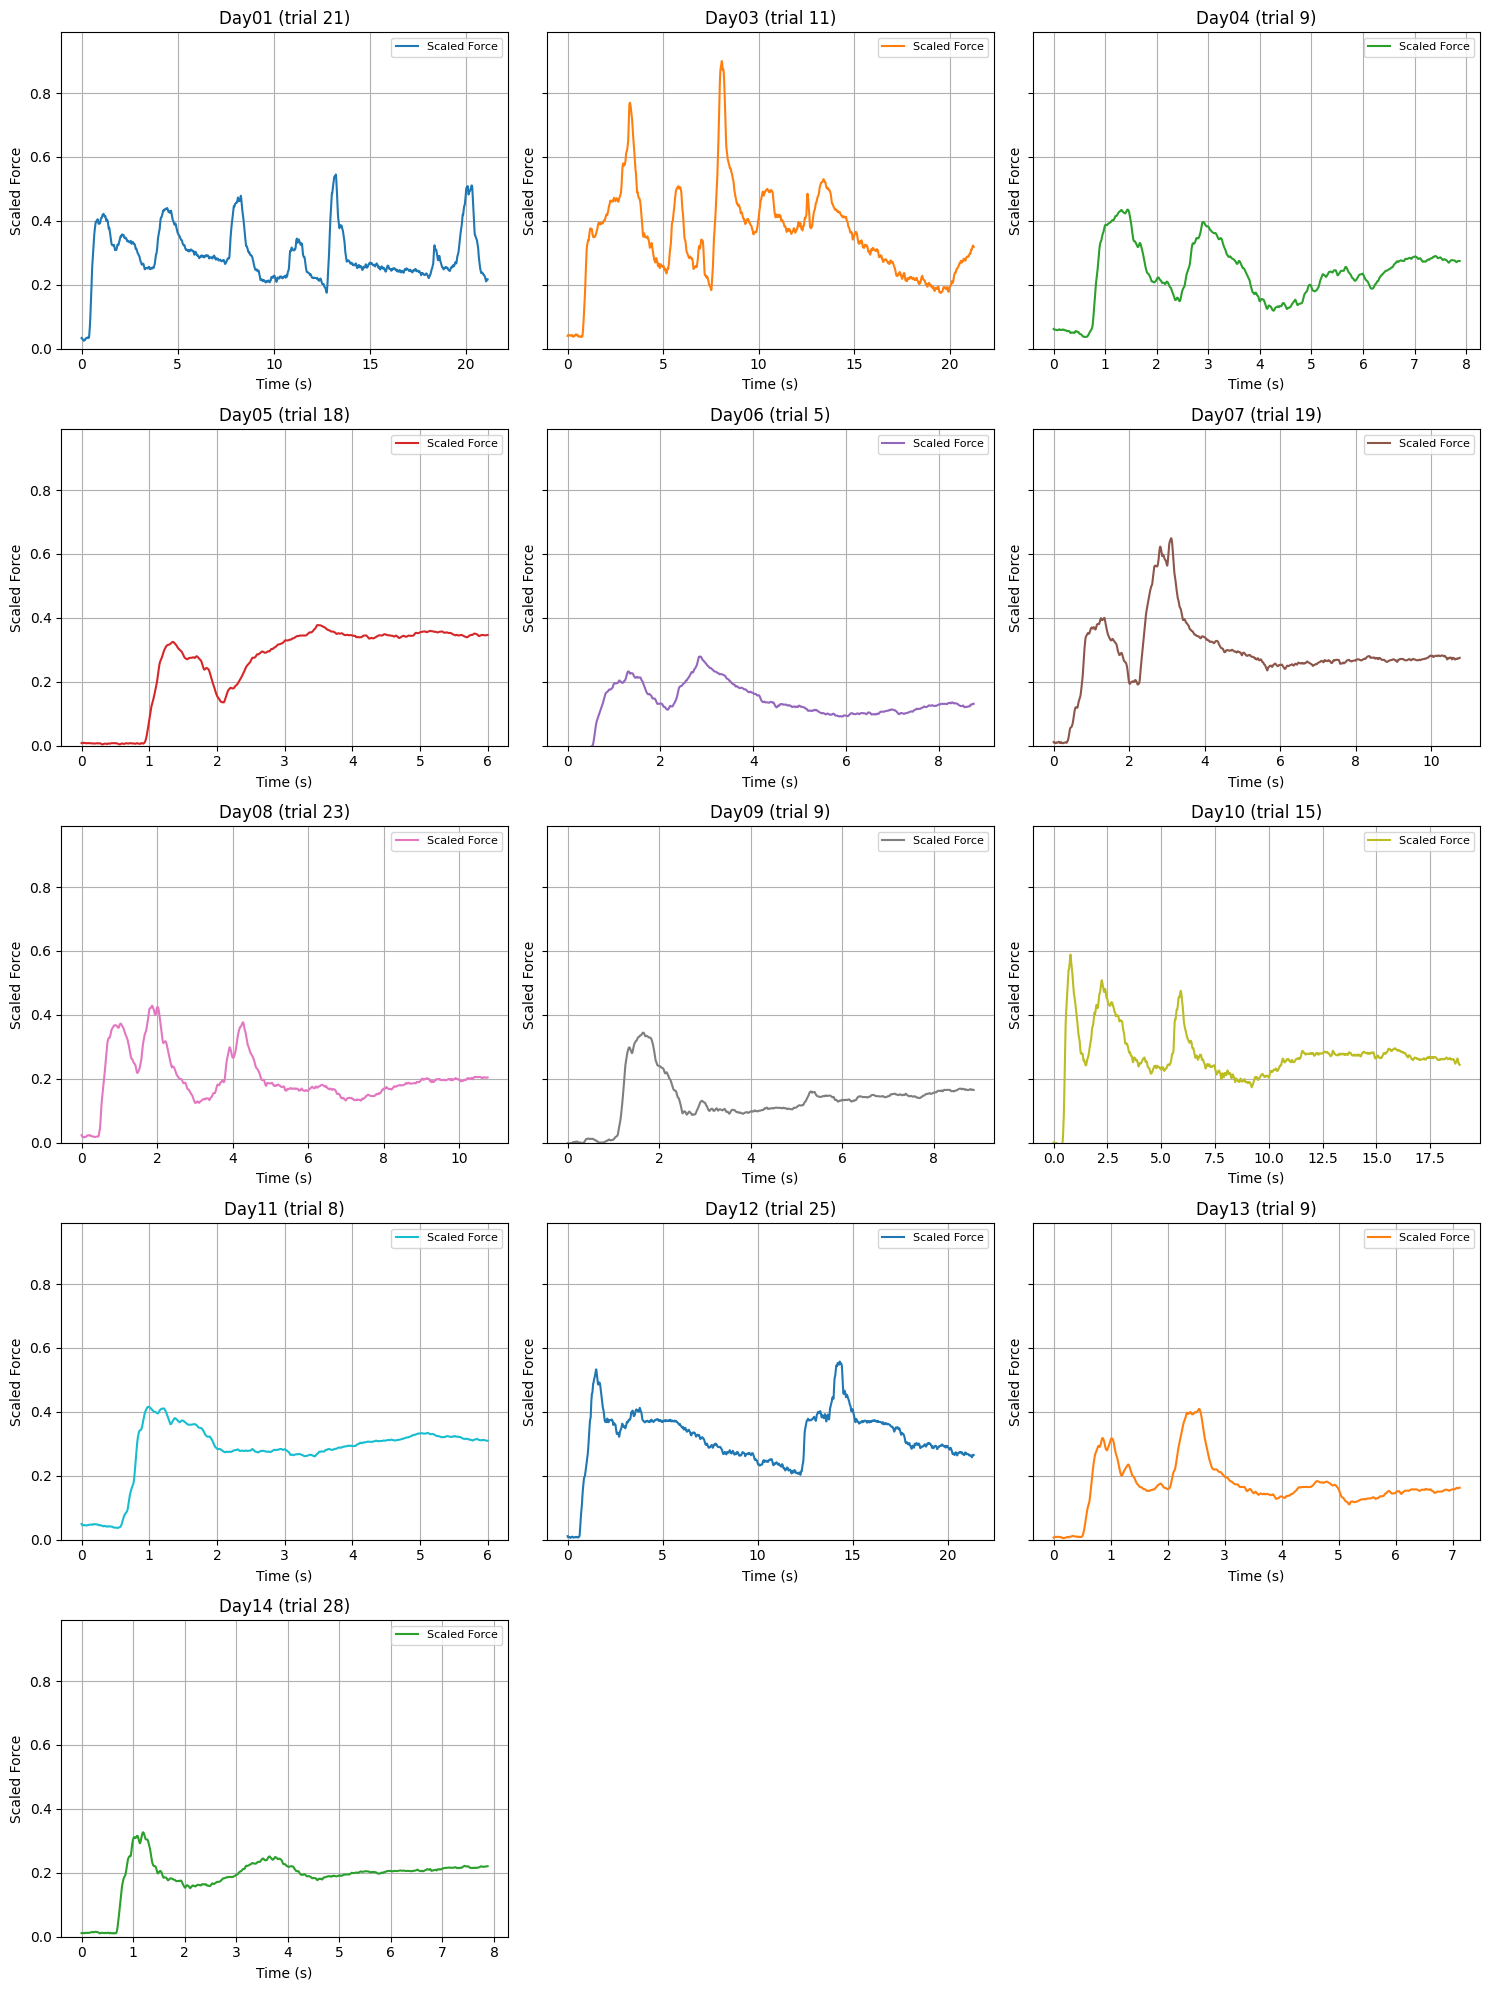

In [49]:
s1_trials = [21, 11, 9, 18, 5, 19, 23, 9, 15, 8, 25, 9, 28]
import os
import re
import pickle

import numpy as np
from scipy.interpolate import interp1d
import matplotlib.pyplot as plt
import matplotlib.cm as cm
def extract_day(filename):
    match = re.search(r"(Day\d{2})", filename)
    return match.group(1) if match else None

def extract_trial(filename):
    match = re.search(r'_(\d+)[^0-9]', filename)
    return int(match.group(1)) if match else 0

def compute_representative_trial(directory_path, save_dir, file_prefix="represetative_trial", target_max=0.4, fsamp=2048, plot=True,trial_numbers_by_day=None):

    pkl_files = [f for f in os.listdir(directory_path) if f.endswith(".pkl")]
    files_by_day = {}
    for file in pkl_files:
        day = extract_day(file)
        if day is not None:
            files_by_day.setdefault(day, []).append(file)

    session_days = sorted(files_by_day.keys())
    for day in session_days:
        files_by_day[day].sort(key=extract_trial)

    # if list is given, align it to session_days
    day_to_trialnum = None
    if isinstance(trial_numbers_by_day, list):
        if len(trial_numbers_by_day) != len(session_days):
            raise ValueError(
                f"Length of trial_numbers_by_day list ({len(trial_numbers_by_day)}) "
                f"must match number of days ({len(session_days)})."
            )
        day_to_trialnum = {day: tn for day, tn in zip(session_days, trial_numbers_by_day)}
    elif isinstance(trial_numbers_by_day, dict):
        day_to_trialnum = trial_numbers_by_day
    else:
        raise ValueError("Provide trial_numbers_by_day (list or dict) to select a specific trial per day.")

    average_force_by_day = {}
    time_by_day = {}

    for day in session_days:
        session_files = files_by_day[day]

        # Load all trial forces for the day
        raw_forces, trial_lengths, trial_nums = [], [], []
        for file_name in session_files:
            file_path = os.path.join(directory_path, file_name)
            with open(file_path, 'rb') as f:
                data = pickle.load(f)
            force = np.array(data['Force'].tolist())[0]
            raw_forces.append(force)
            trial_lengths.append(len(force))
            trial_nums.append(extract_trial(file_name))

        # Use the specific trial only (no averaging)
        selected_trialnum = int(day_to_trialnum[day])
        candidates = [i for i, tn in enumerate(trial_nums) if tn == selected_trialnum]
        if not candidates:
            raise ValueError(f"Day {day}: trial number {selected_trialnum} not found in filenames {trial_nums}.")
        idx = candidates[0]
        selected_force = raw_forces[idx]

        min_length = len(selected_force)
        new_time = np.linspace(0, 1, min_length)
        old_time = np.linspace(0, 1, len(selected_force))
        interp_func = interp1d(old_time, selected_force, kind='linear')
        downsampled = interp_func(new_time)

        mean_force = downsampled  # using the selected trial only
        std_force = np.zeros_like(mean_force)  # no variability when not averaging
        time_axis = np.linspace(0, len(selected_force) / fsamp, min_length)

        average_force_by_day[day] = {
            'mean': mean_force,
            'std': std_force,
            'selected_trialnum': selected_trialnum
        }
        time_by_day[day] = time_axis

    all_max = max(np.max(average_force_by_day[day]['mean']) for day in session_days)
    scaling_factor = target_max / all_max if all_max > 0 else 1.0
    print(f"Global maximum force (before scaling): {all_max:.4f}")
    print(f"Scaling factor to apply: {scaling_factor:.4f}")

    os.makedirs(save_dir, exist_ok=True)

    for day in session_days:
        mean_force = average_force_by_day[day]['mean']
        scaled_force = mean_force * scaling_factor

        sel_trial = average_force_by_day[day]['selected_trialnum']
        suffix = f"_trial{sel_trial:02d}"

        filename = f"{file_prefix}_{day}.npy"
        save_path = os.path.join(save_dir, filename)
        # np.save(save_path , scaled_force)
        print(f"Saved scaled force for {day} to {save_path}")

    if plot:
        cols = 3
        rows = int(np.ceil(len(session_days) / cols))
        fig, axes = plt.subplots(rows, cols, figsize=(15, 4 * rows), sharex=False, sharey=True)
        axes = axes.flatten()
        cmap = cm.get_cmap("tab10")

        for i, day in enumerate(session_days):
            mean = average_force_by_day[day]['mean'] * scaling_factor
            t    = time_by_day[day]
            color = cmap(i % 10)
            sel_trial = average_force_by_day[day]['selected_trialnum']

            ax = axes[i]
            ax.plot(t, mean, color=color, label='Scaled Force')
            title_tag = f"{day} (trial {sel_trial})"
            ax.set_title(title_tag, fontsize=12)
            ax.set_xlabel("Time (s)")
            ax.set_ylabel("Scaled Force")
            ax.set_ylim([0, target_max * 1.1])
            ax.grid(True)
            ax.legend(fontsize=8)

        # remove unused axes
        for j in range(i + 1, len(axes)):
            fig.delaxes(axes[j])

        plt.tight_layout()
        plt.show()
        
        
        
compute_representative_trial(
    directory_path="/Users/nmt121/Desktop/DATA/S1",
    save_dir="/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Scaled_force/S1/",
    file_prefix="force_S111111",
    target_max=.9,
    trial_numbers_by_day=[21, 11, 9, 18, 5, 19, 23, 9, 15, 8, 25, 9, 28],
    plot=True
)


Day01 trial 02: mean_before=0.0333 → target_mean=0.4000 scale=12.020894 (mean_after=0.4000)  -> Day01_trial02.npy
Day01 trial 05: mean_before=0.0331 → target_mean=0.4000 scale=12.090832 (mean_after=0.4000)  -> Day01_trial05.npy
Day01 trial 09: mean_before=0.0311 → target_mean=0.4000 scale=12.867277 (mean_after=0.4000)  -> Day01_trial09.npy
Day01 trial 10: mean_before=0.0328 → target_mean=0.4000 scale=12.184964 (mean_after=0.4000)  -> Day01_trial10.npy
Day01 trial 13: mean_before=0.0290 → target_mean=0.4000 scale=13.782487 (mean_after=0.4000)  -> Day01_trial13.npy
Day01 trial 17: mean_before=0.0277 → target_mean=0.4000 scale=14.424365 (mean_after=0.4000)  -> Day01_trial17.npy
Day01 trial 21: mean_before=0.0249 → target_mean=0.4000 scale=16.075426 (mean_after=0.4000)  -> Day01_trial21.npy
Day01 trial 24: mean_before=0.0436 → target_mean=0.4000 scale=9.169970 (mean_after=0.4000)  -> Day01_trial24.npy
Day01 trial 26: mean_before=0.0326 → target_mean=0.4000 scale=12.261680 (mean_after=0.400

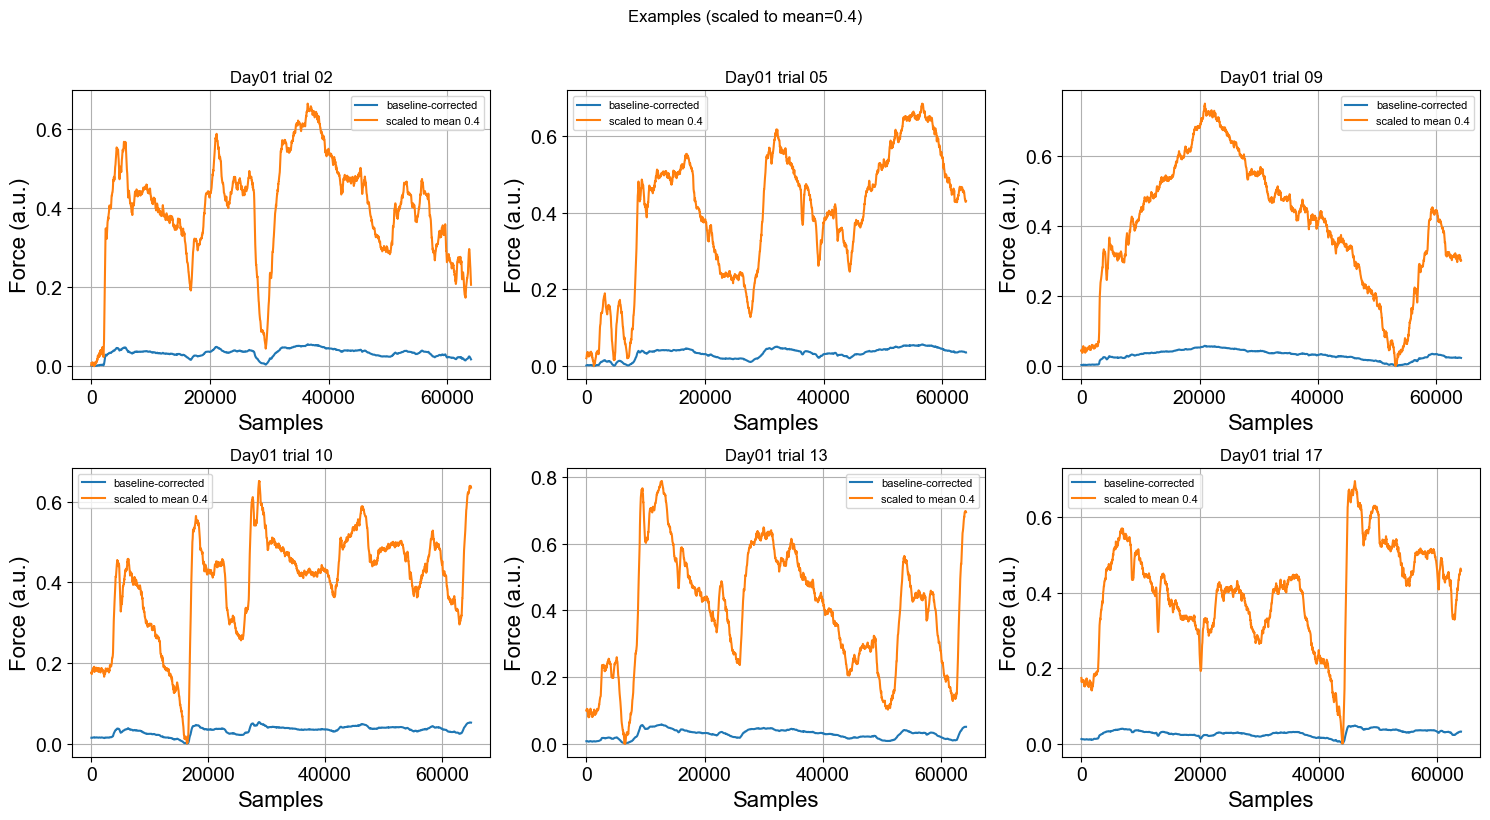

In [98]:
import os, re, csv, pickle
import numpy as np
from typing import Optional
import matplotlib.pyplot as plt

# --- helpers ---
def extract_day(filename: str) -> Optional[str]:
    m = re.search(r"(Day\d{2})", filename)
    return m.group(1) if m else None

def extract_trial(filename: str) -> int:
    m = re.search(r'_(\d+)[^0-9]', filename)
    return int(m.group(1)) if m else 0

def _safe_force_from_pickle(data) -> np.ndarray:
    try:
        x = np.array(data['Force']).squeeze()
        if x.ndim > 1:
            x = np.array(data['Force'].tolist())[0].squeeze()
    except Exception:
        x = np.array(data['Force'].tolist())[0].squeeze()
    return np.asarray(x, float)

def scale_and_save_all_trials_mean(
    directory_path: str,
    save_dir: str,
    target_mean: float = 0.3,
    plot_examples: bool = True,
    n_examples: int = 6,
    overwrite: bool = True,
    verbose: bool = True,
    manifest_name: str = "manifest_mean.csv"
):
    """
    For every *.pkl in directory_path:
      1) load Force
      2) baseline-correct per trial (subtract min so min==0)
      3) scale whole trace so mean == target_mean
      4) save as .npy to save_dir: <Day>_trial<NN>_06.npy

    Writes a manifest CSV with:
      (day, trial, src_file, out_file, mean_before, target_mean, scale_factor)
    """
    os.makedirs(save_dir, exist_ok=True)

    pkl_files = [f for f in os.listdir(directory_path) if f.endswith(".pkl")]
    if not pkl_files:
        raise FileNotFoundError(f"No .pkl files found in {directory_path}")

    # group by day (order nicely)
    files_by_day = {}
    for f in pkl_files:
        day = extract_day(f)
        if day is not None:
            files_by_day.setdefault(day, []).append(f)

    session_days = sorted(files_by_day.keys())
    for day in session_days:
        files_by_day[day].sort(key=extract_trial)

    manifest_rows = []
    ex_plots = []

    for day in session_days:
        for fname in files_by_day[day]:
            trial = extract_trial(fname)
            src_path = os.path.join(directory_path, fname)

            # load force
            with open(src_path, "rb") as f:
                data = pickle.load(f)
            force = _safe_force_from_pickle(data)

            # baseline-correct and handle NaNs
            f0 = np.asarray(force, float)
            if np.any(~np.isfinite(f0)):
                finite = np.isfinite(f0)
                repl = np.nanmedian(f0[finite]) if np.any(finite) else 0.0
                f0 = np.nan_to_num(f0, nan=repl)
            f0 = f0 - np.min(f0)  # min==0

            mean_before = float(np.mean(f0)) if f0.size else 0.0

            if mean_before <= 0.0:
                scaled = np.zeros_like(f0)
                scale_factor = 0.0
            else:
                scale_factor = float(target_mean) / mean_before
                scaled = f0 * scale_factor  # do NOT clip; we want mean to be exact

            out_name = f"{day}_trial{trial:02d}.npy"
            out_path = os.path.join(save_dir, out_name)

            if overwrite or (not os.path.exists(out_path)):
                np.save(out_path, scaled)

            if verbose:
                mean_after = float(np.mean(scaled)) if scaled.size else 0.0
                print(f"{day} trial {trial:02d}: mean_before={mean_before:.4f} "
                      f"→ target_mean={target_mean:.4f} scale={scale_factor:.6f} "
                      f"(mean_after={mean_after:.4f})  -> {out_name}")

            manifest_rows.append([
                day, trial, fname, out_name,
                f"{mean_before:.8f}",
                f"{target_mean:.8f}",
                f"{scale_factor:.8f}",
            ])

            # store a few examples to plot
            if plot_examples and len(ex_plots) < n_examples:
                ex_plots.append((day, trial, f0, scaled))

    # write manifest CSV
    manifest_path = os.path.join(save_dir, manifest_name)
    with open(manifest_path, "w", newline="") as cf:
        w = csv.writer(cf)
        w.writerow(["day","trial","src_file","out_file","mean_before","target_mean","scale_factor"])
        w.writerows(manifest_rows)

    if verbose:
        print(f"\nWrote manifest: {manifest_path}")

    # example plots
    if plot_examples and ex_plots:
        cols = 3
        rows = int(np.ceil(len(ex_plots) / cols))
        fig, axes = plt.subplots(rows, cols, figsize=(15, 4 * rows), sharex=False, sharey=False)
        axes = np.atleast_1d(axes).ravel()
        for i, (d, tr, raw, scaled) in enumerate(ex_plots):
            ax = axes[i]
            ax.plot(raw, label="baseline-corrected")
            ax.plot(scaled, label=f"scaled to mean {target_mean}")
            ax.set_title(f"{d} trial {tr:02d}")
            ax.set_xlabel("Samples")
            ax.set_ylabel("Force (a.u.)")
            ax.legend(fontsize=8)
            ax.grid(True)
        for j in range(i + 1, len(axes)):
            fig.delaxes(axes[j])
        fig.suptitle(f"Examples (scaled to mean={target_mean})", y=1.02)
        plt.tight_layout()
        plt.show()


# ===== Example call: center MEAN of each signal at 0.3 =====
scale_and_save_all_trials_mean(
    directory_path="/Users/nmt121/Desktop/DATA/S7",
    save_dir="/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Scaled_force/S7_alltrials/",
    target_mean=0.4,
    plot_examples=True,
    n_examples=6,
    overwrite=True,
    verbose=True
)


In [29]:
# import os
# import re
# import pickle
# import h5py
# import numpy as np
# import matplotlib.pyplot as plt



# def extract_day(filename):
#     match = re.search(r"(Day\d{2})", filename)
#     return int(match.group(1)[3:]) if match else None

# def extract_trial(filename):
#     match = re.search(r'_(\d+)[^0-9]', filename)
#     return int(match.group(1)) if match else 0

# def compute_avg_firing_rate(spike_times, sampling_rate):
#     if len(spike_times) < 2:
#         return None
#     ISIs = np.diff(spike_times) / sampling_rate
#     return 1 / np.mean(ISIs)

# def load_simulated_rates(jld2_file_paths):
#     sim_rates_by_day = {}
#     for path in jld2_file_paths:
#         day_match = re.search(r'force(\d+)_firing_rates\.jld2', path)
#         if not day_match:
#             continue
#         day = int(day_match.group(1))

#         with h5py.File(path, 'r') as f:
#             if 'avg_rates_per_neuron' in f:
#                 rates = f['avg_rates_per_neuron'][:]
#                 sim_rates_by_day[day] = rates
#                 print(sim_rates_by_day[day])
#             else:
#                 print(f"'avg_rates_per_neuron' not found in {path}")
#     return sim_rates_by_day

# def compute_firing_rate_histograms_with_sim(folder_path, Fsamp, jld2_file_paths):
#     sim_data = load_simulated_rates(jld2_file_paths)
#     pkl_files = sorted(
#         [f for f in os.listdir(folder_path) if f.endswith('.pkl')],
#         key=lambda x: (extract_day(x), extract_trial(x))
#     )
#     day_files = {}
#     for file in pkl_files:
#         day = extract_day(file)
#         if day is not None:
#             day_files.setdefault(day, []).append(file)

#     n_days = len(day_files)
#     n_cols = 4
#     n_rows = int(np.ceil(n_days / n_cols))
#     fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows))
#     axes = axes.flatten()

#     for i, (day, files) in enumerate(sorted(day_files.items())):
#         all_firing_rates = []
#         for file in files:
#             with open(os.path.join(folder_path, file), 'rb') as f:
#                 data = pickle.load(f)
#             MU_array = np.array(data['MU'])

#             for neuron_idx in range(MU_array.shape[0]):
#                 spike_times = np.where(MU_array[neuron_idx] == 1)[0]
#                 fr = compute_avg_firing_rate(spike_times, Fsamp)
#                 if fr is not None and fr <= 80:
#                     all_firing_rates.append(fr)

#         ax = axes[i]
#         bin_edges = np.linspace(0, 40, 21)

#         ax.hist(all_firing_rates, bins=bin_edges, color='blue', alpha=0.4,
#                 label='Experimental', density=True, edgecolor='black', linewidth=1.2)

#         if day in sim_data:
#             ax.hist(sim_data[day], bins=bin_edges, color='red', alpha=0.4,
#                     label='Simulated', density=True, edgecolor='black', linewidth=1.2)

#         # ax.set_title(f'Day {day}: {len(all_firing_rates)} neurons')  # Title removed
#         ax.set_xlabel('Avg firing rate (Hz)', fontsize=16)
#         ax.set_ylabel('Density', fontsize=16)

#         # Remove legend
#         # ax.legend()

#         # Remove top and right spines
#         ax.spines['right'].set_visible(False)
#         ax.spines['top'].set_visible(False)

#         # Make ticks bigger
#         ax.tick_params(axis='both', which='major', labelsize=16)

#     for j in range(i + 1, len(axes)):
#         fig.delaxes(axes[j])

#     plt.tight_layout()
#     return fig



# folder_path = "/Users/nmt121/Desktop/DATA/S1"
# Fsamp = 2048

# jld2_file_paths = [
    
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force1_firing_rates_last_trial.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force3_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force4_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force5_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force6_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force7_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force8_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force9_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force10_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force11_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force12_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force13_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force14_firing_rates_last_trial.jld2',
    
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force1_firing_rates_rep_.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force3_firing_rates_rep_.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force4_firing_rates_rep_.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force5_firing_rates_rep_.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force6_firing_rates_rep_.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force7_firing_rates_rep_.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force8_firing_rates_rep_.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force9_firing_rates_rep_.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force10_firing_rates_rep_.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force11_firing_rates_rep_.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force12_firing_rates_rep_.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force13_firing_rates_rep_.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force14_firing_rates_rep_.jld2',
    

    
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S2/force2_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S2/force3_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S2/force4_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S2/force7_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S2/force13_firing_rates.jld2',
    
    
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force1_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force2_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force3_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force4_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force5_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force7_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force10_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force11_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force12_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force13_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S3/force14_firing_rates.jld2',
    
    
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S4/force1_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S4/force3_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S4/force7_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S4/force8_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S4/force9_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S4/force10_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S4/force11_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S4/force12_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S4/force13_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S4/force14_firing_rates.jld2',
    
    
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S6/force1_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S6/force3_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S6/force4_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S6/force5_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S6/force8_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S6/force9_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S6/force10_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S6/force11_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S6/force12_firing_rates.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S6/force13_firing_rates.jld2', 
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S6/force14_firing_rates.jld2',
    
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force1_firing_rates7.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force2_firing_rates7.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force3_firing_rates7.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force4_firing_rates7.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force5_firing_rates7.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force6_firing_rates7.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force7_firing_rates7.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force8_firing_rates7.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force9_firing_rates7.jld2',
#     # '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/force10_firing_rates7.jld2',




# ]

# fig = compute_firing_rate_histograms_with_sim(folder_path, Fsamp, jld2_file_paths)
# # plt.savefig('/Users/nmt121/Desktop/Figures/FRdistributions_S1.pdf', dpi=300, bbox_inches='tight')
# plt.show()



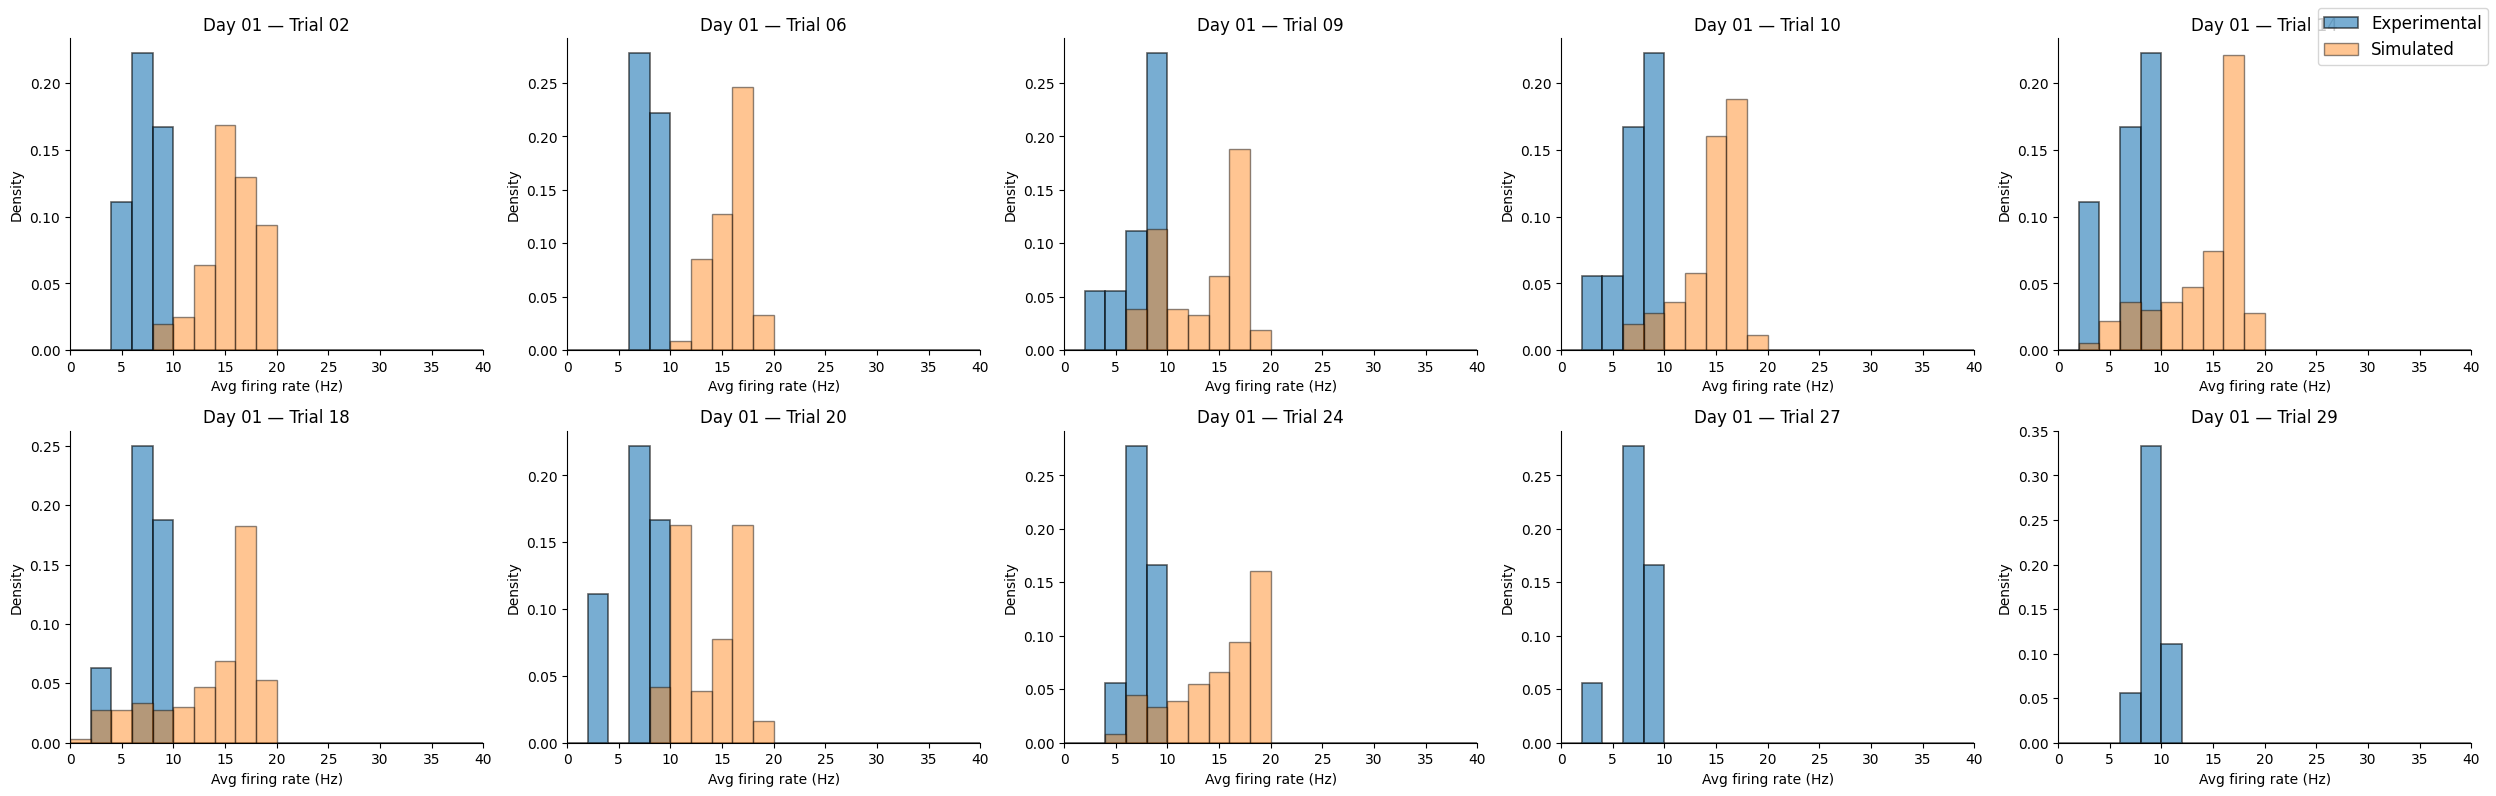

In [76]:
import os, re, pickle, h5py
import numpy as np
import matplotlib.pyplot as plt

# ------------ paths & settings ------------
exp_folder = "/Users/nmt121/Desktop/DATA/S2"
    ############################################
    ############################################
    ############################################
    ############################################  
sim_day1   = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S2/new/Day1"

Fs_exp = 2048
FR_CAP = 80.0
BINS   = np.linspace(0, 40, 21)

# ------------ helpers ------------
def avg_fr_from_spike_times(idx, fs):
    if idx.size < 2:
        return None
    isi = np.diff(idx) / fs
    m = isi.mean()
    return None if m <= 0 else 1.0 / m

def parse_exp_day_trial(fname):
    # "…Day01…_trial17…" or "…Day1…_17…"
    mday = re.search(r"Day0*(\d+)", fname)
    mtr  = re.search(r"(?:_trial|_)(\d+)(?!\d)", fname)
    if not mday or not mtr:
        return None
    return int(mday.group(1)), int(mtr.group(1))

def _get_MU_array(data):
    try:
        MU = np.array(data["MU"])
        if MU.dtype == object:
            MU = np.array(data["MU"].tolist())
        return MU
    except Exception:
        return np.array(data["MU"].tolist())

def _read_jld2_array(h: h5py.File, key: str):
    if key in h and isinstance(h[key], h5py.Dataset) and h[key].dtype.kind in "biuf":
        return h[key][:]
    if f"{key}/value" in h and isinstance(h[f"{key}/value"], h5py.Dataset):
        d = h[f"{key}/value"]
        if d.dtype.kind in "biuf":
            return d[:]
    if key in h and isinstance(h[key], h5py.Group):
        g = h[key]
        if "value" in g and isinstance(g["value"], h5py.Dataset) and g["value"].dtype.kind in "biuf":
            return g["value"][:]
    return None

# ------------ collectors ------------
def collect_exp_day1_by_trial(exp_dir, fs=2048, fr_cap=80.0):
    """Experimental FRs grouped by TRIAL, only for Day 1."""
    by_trial = {}
    for f in os.listdir(exp_dir):
        if not f.endswith(".pkl"):
            continue
        parsed = parse_exp_day_trial(f)
        if parsed is None:
            continue
        day, trial = parsed
        ##############
        ##############
        ##############
        if day != 2:
            continue
        with open(os.path.join(exp_dir, f), "rb") as fh:
            data = pickle.load(fh)
        MU = _get_MU_array(data)

        frs = []
        for i in range(MU.shape[0]):
            idx = np.flatnonzero(MU[i] == 1)
            fr = avg_fr_from_spike_times(idx, fs)
            if fr is not None and fr <= fr_cap:
                frs.append(fr)
        if frs:
            by_trial.setdefault(trial, []).extend(frs)
    return by_trial

def collect_sim_day1_by_trial(sim_dir, fr_cap=80.0):

    """Sim FRs for Day 1: files like force{trial}_firing_rates3.jld2."""
    by_trial = {}
    if not os.path.isdir(sim_dir):
        return by_trial
    for f in os.listdir(sim_dir):
        if not (f.endswith(".jld2") or f.endswith(".h5")):
            continue
    
    ############################################
    ############################################
    ############################################
    ############################################      
        m = re.fullmatch(r"force(\d+)_firing_rates\.(?:jld2|h5)", f)
        if not m:
            continue
        trial = int(m.group(1))
        path = os.path.join(sim_dir, f)
        try:
            with h5py.File(path, "r") as h:
                rates = _read_jld2_array(h, "avg_rates_per_neuron")
                if rates is None:
                    rates = _read_jld2_array(h, "firing_rates")
                if rates is None:
                    continue
                rates = np.asarray(rates, float)
                rates = rates[np.isfinite(rates)]
                rates = rates[rates <= fr_cap]
                if rates.size:
                    by_trial[trial] = rates
        except Exception as e:
            print("could not open", path, "→", e)
    return by_trial

# ------------ run ------------
exp_day1 = collect_exp_day1_by_trial(exp_folder, fs=Fs_exp, fr_cap=FR_CAP)
sim_day1 = collect_sim_day1_by_trial(sim_day1, fr_cap=FR_CAP)

trials = sorted(set(exp_day1.keys()) | set(sim_day1.keys()))
if not trials:
    raise RuntimeError("No Day 1 trials found in exp or sim folders.")

# ------------ plot per TRIAL (Day 1) ------------
cols = 5
rows = int(np.ceil(len(trials) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(5*cols, 4*rows))
axes = np.atleast_1d(axes).ravel()

for i, tr in enumerate(trials):
    ax = axes[i]
    if tr in exp_day1:
        ax.hist(exp_day1[tr], bins=BINS, density=True, alpha=0.6,
                edgecolor="black", linewidth=1.2, label="Experimental")
    if tr in sim_day1:
        ax.hist(sim_day1[tr], bins=BINS, density=True, alpha=0.45,
                edgecolor="black", linewidth=1.0, label="Simulated")

    ax.set_title(f"Day 01 — Trial {tr:02d}")
    ax.set_xlim(0, 40)
    ax.set_xlabel("Avg firing rate (Hz)")
    ax.set_ylabel("Density")
    ax.spines["right"].set_visible(False)
    ax.spines["top"].set_visible(False)
    ax.tick_params(axis="both", which="major", labelsize=10)

# remove empty axes
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

# figure-level legend (if anything was plotted)
for ax in axes:
    handles, labels = ax.get_legend_handles_labels()
    if handles:
        fig.legend(handles, labels, loc="upper right", fontsize=12)
        break

plt.tight_layout()
plt.show()


## Code to optmize force input

In [ ]:
# ------------ paths & settings ------------
exp_folder = "/Users/nmt121/Desktop/DATA/S1"

Fs_exp = 2048
FR_CAP = 80.0
BINS   = np.linspace(0, 40, 21)  # 20 bins => 2 Hz wide
BIN_CENTERS = 0.5 * (BINS[:-1] + BINS[1:])

# ------------ helpers ------------
def avg_fr_from_spike_times(idx, fs):
    if idx.size < 2:
        return None
    isi = np.diff(idx) / fs
    m = isi.mean()
    return None if m <= 0 else 1.0 / m

def parse_exp_day_trial(fname):
    # supports "…Day01…_trial17…" or "…Day1…_17…"
    mday = re.search(r"Day0*(\d+)", fname)
    mtr  = re.search(r"(?:_trial|_)(\d+)(?!\d)", fname)
    if not mday or not mtr:
        return None
    return int(mday.group(1)), int(mtr.group(1))

def _get_MU_array(data):
    try:
        MU = np.array(data["MU"])
        if MU.dtype == object:
            MU = np.array(data["MU"].tolist())
        return MU
    except Exception:
        return np.array(data["MU"].tolist())

# ------------ collect avg FRs per (day, trial) ------------
frs_by_day_trial = {}  # {(day, trial): [fr1, fr2, ...]}
for f in os.listdir(exp_folder):
    if not f.endswith(".pkl"):
        continue
    parsed = parse_exp_day_trial(f)
    if parsed is None:
        continue
    day, trial = parsed

    with open(os.path.join(exp_folder, f), "rb") as fh:
        data = pickle.load(fh)

    MU = _get_MU_array(data)
    # MU shape: (n_units, n_samples) with 0/1 spikes per sample

    frs = []
    for i in range(MU.shape[0]):
        idx = np.flatnonzero(MU[i] == 1)
        fr = avg_fr_from_spike_times(idx, Fs_exp)
        if fr is not None and np.isfinite(fr) and fr <= FR_CAP:
            frs.append(float(fr))

    if frs:
        frs_by_day_trial.setdefault((day, trial), []).extend(frs)

# ------------ reduce to peak-bin Hz per (day, trial) ------------
peak_rate_by_day_trial = {}  # {day: {trial: {"peak_hz": x, "peak_count": c, "n_units": n}}}
for (day, trial), frs in frs_by_day_trial.items():
    counts, _ = np.histogram(frs, bins=BINS)
    if counts.sum() == 0:
        peak_hz = None
        peak_count = 0
    else:
        k = int(np.argmax(counts))
        peak_hz = float(BIN_CENTERS[k])
        peak_count = int(counts[k])

    peak_rate_by_day_trial.setdefault(day, {})[trial] = {
        "peak_hz": peak_hz,
        "peak_count": peak_count,
        "n_units": len(frs),
    }

# ------------ optional: pretty print (sorted) ------------
for day in sorted(peak_rate_by_day_trial.keys()):
    print(f"\nDay {day:02d}")
    for trial in sorted(peak_rate_by_day_trial[day].keys()):
        entry = peak_rate_by_day_trial[day][trial]
        print(f"  Trial {trial:02d}: peak={entry['peak_hz']} Hz  "
              f"(count={entry['peak_count']}, n_units={entry['n_units']})")

# ------------ optional: save to disk ------------
import json
out_json = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/S1_peak_rate_histogram.json"
with open(out_json, "w") as f:
    json.dump(peak_rate_by_day_trial, f, indent=2)
print(f"\nSaved: {out_json}")



Day 01
  Trial 01: peak=7.0 Hz  (count=5, n_units=15)
  Trial 06: peak=11.0 Hz  (count=5, n_units=15)
  Trial 09: peak=11.0 Hz  (count=7, n_units=15)
  Trial 11: peak=9.0 Hz  (count=5, n_units=15)
  Trial 14: peak=9.0 Hz  (count=4, n_units=15)
  Trial 17: peak=9.0 Hz  (count=6, n_units=15)
  Trial 21: peak=9.0 Hz  (count=6, n_units=15)
  Trial 24: peak=39.0 Hz  (count=1, n_units=11)
  Trial 27: peak=9.0 Hz  (count=4, n_units=15)
  Trial 30: peak=9.0 Hz  (count=6, n_units=15)

Day 03
  Trial 03: peak=11.0 Hz  (count=5, n_units=11)
  Trial 04: peak=9.0 Hz  (count=7, n_units=11)
  Trial 09: peak=9.0 Hz  (count=6, n_units=11)
  Trial 11: peak=9.0 Hz  (count=4, n_units=11)
  Trial 14: peak=9.0 Hz  (count=6, n_units=11)
  Trial 18: peak=11.0 Hz  (count=3, n_units=11)
  Trial 21: peak=9.0 Hz  (count=4, n_units=11)
  Trial 23: peak=11.0 Hz  (count=4, n_units=11)
  Trial 26: peak=11.0 Hz  (count=4, n_units=11)
  Trial 29: peak=11.0 Hz  (count=5, n_units=11)

Day 04
  Trial 01: peak=11.0 Hz  (c

In [38]:
import os, re, pickle, numpy as np, h5py

# --- helpers (your patterns) ---
def extract_day(filename):
    m = re.search(r"(Day\d{2})", filename)
    return m.group(1) if m else None

def extract_trial(filename):
    m = re.search(r'_(\d+)[^0-9]', filename)
    return int(m.group(1)) if m else 0

def _safe_force_from_pickle(data):
    try:
        x = np.array(data['Force']).squeeze()
        if x.ndim > 1:
            x = np.array(data['Force'].tolist())[0].squeeze()
    except Exception:
        x = np.array(data['Force'].tolist())[0].squeeze()
    return np.asarray(x, float)

def save_all_trials_raw_to_hdf5(
    directory_path: str,
    out_dir: str,
    subject: str = "S1",
    dataset_name: str = "force",
    fsamp: float = 2048.0,
    overwrite: bool = True,
    verbose: bool = True,
):
    os.makedirs(out_dir, exist_ok=True)

    pkl_files = [f for f in os.listdir(directory_path) if f.endswith(".pkl")]
    if not pkl_files:
        raise FileNotFoundError(f"No .pkl files found in {directory_path}")

    # group & order by day, trial
    files_by_day = {}
    for f in pkl_files:
        day = extract_day(f)
        if day is not None:
            files_by_day.setdefault(day, []).append(f)
    for day in files_by_day:
        files_by_day[day].sort(key=extract_trial)

    for day in sorted(files_by_day.keys()):
        for fname in files_by_day[day]:
            trial = extract_trial(fname)
            src_path = os.path.join(directory_path, fname)

            # load raw force (no scaling, no baseline correction)
            with open(src_path, "rb") as f:
                data = pickle.load(f)
            force = _safe_force_from_pickle(data)  # 1D np.float64

            # make time vector in seconds
            time = np.arange(force.size) / fsamp

            out_name = f"{subject}_{day}_trial{trial:02d}_force.h5"
            out_path = os.path.join(out_dir, out_name)
            if (not overwrite) and os.path.exists(out_path):
                if verbose:
                    print(f"skip (exists): {out_name}")
                continue

            # write HDF5
            with h5py.File(out_path, "w") as h:
                # save both force and time
                h.create_dataset(dataset_name, data=force, compression="gzip", shuffle=True)
                h.create_dataset("time", data=time, compression="gzip", shuffle=True)
                # useful attrs
                h.attrs["subject"] = subject
                h.attrs["day"] = day            # e.g., "Day03"
                h.attrs["trial"] = trial        # int
                h.attrs["Fs"] = fsamp
                h.attrs["n_samples"] = int(force.size)
                h.attrs["src_file"] = fname
                # quick stats
                h.attrs["min"] = float(np.min(force)) if force.size else np.nan
                h.attrs["max"] = float(np.max(force)) if force.size else np.nan
                h.attrs["mean"] = float(np.mean(force)) if force.size else np.nan

            if verbose:
                print(f"saved: {out_name}  (n={force.size}, min={force.min():.4f}, max={force.max():.4f})")

# ---- run ----
save_all_trials_raw_to_hdf5(
    directory_path="/Users/nmt121/Desktop/DATA/S1",
    out_dir="/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Scaled_force/Raw/S1",
    subject="S1",
    dataset_name="force",
    fsamp=2048.0,
    overwrite=True,
    verbose=True,
)


saved: S1_Day01_trial01_force.h5  (n=43264, min=0.0117, max=0.1872)
saved: S1_Day01_trial06_force.h5  (n=43520, min=0.0103, max=0.2007)
saved: S1_Day01_trial09_force.h5  (n=14592, min=0.0071, max=0.1349)
saved: S1_Day01_trial11_force.h5  (n=43520, min=0.0125, max=0.1475)
saved: S1_Day01_trial14_force.h5  (n=43520, min=0.0123, max=0.1618)
saved: S1_Day01_trial17_force.h5  (n=14080, min=0.0115, max=0.1345)
saved: S1_Day01_trial21_force.h5  (n=43264, min=0.0069, max=0.1469)
saved: S1_Day01_trial24_force.h5  (n=28672, min=0.0128, max=0.1411)
saved: S1_Day01_trial27_force.h5  (n=43520, min=0.0102, max=0.1349)
saved: S1_Day01_trial30_force.h5  (n=32512, min=0.0075, max=0.1296)
saved: S1_Day03_trial03_force.h5  (n=43520, min=-0.0006, max=0.2118)
saved: S1_Day03_trial04_force.h5  (n=19456, min=0.0051, max=0.1334)
saved: S1_Day03_trial09_force.h5  (n=43776, min=0.0039, max=0.1962)
saved: S1_Day03_trial11_force.h5  (n=43520, min=0.0101, max=0.2424)
saved: S1_Day03_trial14_force.h5  (n=37632, min

## Get rasters for each of the trials

In [ ]:
from functions_analysis_online_control_exp.create_rasters import *
# fig = create_raster('/Users/nmt121/Desktop/DATA/S7/', Fsamp=1000, extract_day=extract_day, extract_trial=extract_trial)
# plt.show(fig)
# # fig.savefig('/Users/nmt121/Desktop/trial_plot.pdf', dpi=300, bbox_inches='tight')

# Behavioral analysis

## Plot force trajectories for every day and every trial

In [ ]:
from functions_analysis_online_control_exp.force_trajectories import *
# fsamp = 2048  
# highlight_samples = int(3 * fsamp)  #in case one wants to highlight part of the trajectory
# fig = create_force_plots_by_day(directory_path='/Users/nmt121/Desktop/DATA/S1/',fsamp=2048,highlight_samples=1000,extract_day=extract_day,extract_trial=extract_trial)
# plt.show(fig)
# # # plt.savefig('/Users/nmt121/Desktop/RESULTS_ DATA EXP/S7force.pdf', dpi=300, bbox_inches='tight')

### Plot force trajectories from 2 first and 2 last days 

In [181]:
from functions_analysis_online_control_exp.force_trajectories import *

# plot_force_trials_block(
#     directory_path="/Users/nmt121/Desktop/DATA/S7",
#     fsamp=2048,
#     highlight_seconds=3.0,
#     long_trial_thresh_s=19.0,
#     y_max=0.2,
#     tick_size=40,
#     save_path="/Users/nmt121/Desktop/S7force_clean.pdf"
# )

## Measure smoothness of the force signal 

/Users/nmt121/Desktop/Repositories/Motoneuron_Model/functions_analysis_online_control_exp/smoothness_force_signal.py:74: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(data=df, x="Group", y="Smoothness", hue="Day",dodge=True, jitter=0.25, alpha=0.5, size=8,ax=ax, palette="tab10", edgecolor='gray', linewidth=0.2)
/Users/nmt121/Desktop/Repositories/Motoneuron_Model/functions_analysis_online_control_exp/smoothness_force_signal.py:89: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["First sessions", "Last sessions"], fontsize=16)


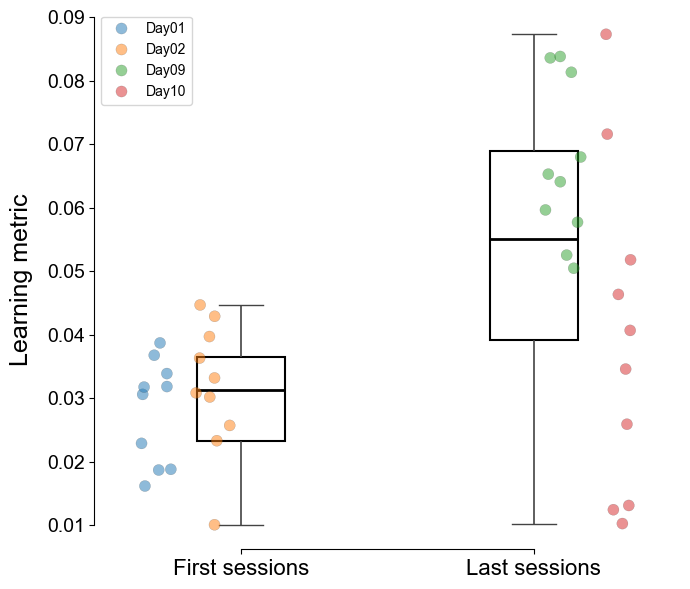

In [106]:
from functions_analysis_online_control_exp.smoothness_force_signal import *

fig = compute_signal_smoothness('/Users/nmt121/Desktop/DATA/S7/', fsamp=2048)
fig.savefig("/Users/nmt121/Desktop/Figures/Smoothness_amplitude_FFT/learningmetric7_amplitudefft.pdf", dpi=300, bbox_inches='tight')

## Success rate

In [114]:
from functions_analysis_online_control_exp.success_rate import *

results = trial_success_rate_per_day('/Users/nmt121/Desktop/DATA/S6/', fsamp=2048)

for day, stats in results.items():
    print(f"{day}: {stats['success_rate']:.1f}% ({stats['n_success']}/{stats['n_total']})")



Day01: 0.0% (0/10)
Day03: 70.0% (7/10)
Day04: 70.0% (7/10)
Day05: 0.0% (0/10)
Day06: 0.0% (0/10)
Day07: 100.0% (10/10)
Day08: 60.0% (6/10)
Day09: 100.0% (10/10)
Day10: 100.0% (10/10)
Day11: 50.0% (5/10)
Day12: 100.0% (10/10)
Day13: 80.0% (8/10)
Day14: 70.0% (7/10)


### Stats for differences in success between first two and last two days

In [84]:
day1 = [40,20,10,0,0,0]
day2 = [50,60,100,30,70,20]
day13 = [10,90,100,30,80,52.9]
day14 = [100,70,100,66.7,70,10]

first_sessions = np.array(day1 + day2)
last_sessions  = np.array(day13 + day14)

print("First sessions mean ± std: %.2f ± %.2f" % (np.mean(first_sessions), np.std(first_sessions)))
print("Last sessions mean ± std:  %.2f ± %.2f" % (np.mean(last_sessions), np.std(last_sessions)))

from scipy import stats
# Independent samples t-test (Welch's)
t_stat, p_val = stats.ttest_ind(first_sessions, last_sessions, equal_var=False)
print("Welch t-test: t = %.3f, p = %.4f" % (t_stat, p_val))

# Mann-Whitney U test (nonparametric alternative)
u_stat, p_u = stats.mannwhitneyu(first_sessions, last_sessions, alternative="two-sided")
print("Mann–Whitney U: U = %.3f, p = %.4f" % (u_stat, p_u))


First sessions mean ± std: 33.33 ± 30.37
Last sessions mean ± std:  64.97 ± 31.62
Welch t-test: t = -2.393, p = 0.0257
Mann–Whitney U: U = 34.000, p = 0.0295


## Take most representative trial

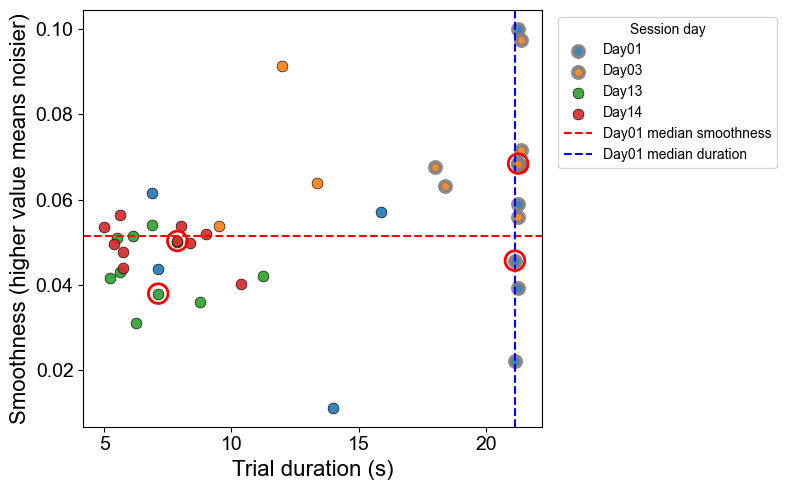

       Day  Trial                      File  TrialDur_s  Smoothness
6    Day01     21  E3_MB01_Day01High_21.pkl      21.125    0.045720
13   Day03     11  E3_MB01_Day03High_11.pkl      21.250    0.068481
22   Day04      9   E3_MB01_Day04High_9.pkl       7.875    0.051828
36   Day05     18  E3_MB01_Day05High_18.pkl       6.000    0.080721
42   Day06      5   E3_MB01_Day06High_5.pkl       8.750    0.034478
57   Day07     19  E3_MB01_Day07High_19.pkl      10.750    0.063988
67   Day08     23  E3_MB01_Day08High_23.pkl      10.750    0.044008
73   Day09      9   E3_MB01_Day09High_9.pkl       8.875    0.040275
84   Day10     15  E3_MB01_Day10High_15.pkl      18.875    0.059173
92   Day11      8   E3_MB01_Day11High_8.pkl       6.000    0.062577
108  Day12     25  E3_MB01_Day12High_25.pkl      21.375    0.062187
112  Day13      9   E3_MB01_Day13High_9.pkl       7.125    0.037995
129  Day14     28  E3_MB01_Day14High_28.pkl       7.875    0.050339


In [ ]:
from functions_analysis_online_control_exp.choose_representative_force_trial import *


df, selected = duration_vs_smoothness_scatter_with_median(
    '/Users/nmt121/Desktop/DATA/S1/', fsamp=2048, high_freq_threshold=5.0,
    keep_first_last=True, annotate=True,
    save_path="/Users/nmt121/Desktop/Figures/dur_vs_smoothness_S7.pdf"
)


## Compute FFT to see frequency content 

In [ ]:
from functions_analysis_online_control_exp.FFT_function import *
# results = plot_fft_and_compute_metric_per_trial('/Users/nmt121/Desktop/DATA/S1/', fsamp=2048, fmin=10.0, max_freq=30)


## Plot firing rate state space (in this case for two first and last 2 sessions)

In [183]:
from functions_analysis_online_control_exp.plot_fr_trajectories import *

# plot_fr_trajectories_block(
#     directory_path="/Users/nmt121/Desktop/DATA/S7",
#     output_path="/Users/nmt121/Desktop/S7_FRxFR.pdf",
#     clip_thresh=35,            # or None
#     smooth_window_s=0.30,      # FR smoothing window (s)
#     xlim=(-2, 35), ylim=(-2, 35),
#     tick_locs=(0,15,30),
#     tick_size=40
# )

## Plot peak count for each day

In [18]:
from functions_analysis_online_control_exp.count_peaks_smoothnes import *

# directory_paths = {"S1": "/Users/nmt121/Desktop/DATA/S1", "S2": "/Users/nmt121/Desktop/DATA/S2","S3": "/Users/nmt121/Desktop/DATA/S3", "S4": "/Users/nmt121/Desktop/DATA/S4", "S6": "/Users/nmt121/Desktop/DATA/S6", "S7": "/Users/nmt121/Desktop/DATA/S7"}

# fig = create_peak_count_summary(directory_paths=directory_paths,fsamp=2048,extract_day=extract_day,extract_trial=extract_trial,lowpass_filter=lowpass_filter)

# Save when ready
# fig.savefig("/Users/nmt121/Desktop/Figures/peaks_summary.pdf", dpi=300, bbox_inches='tight')

# Or display when ready
# plt.show(fig)


## Plot trial duration for all trials

In [ ]:
from functions_analysis_online_control_exp.trial_duration import *

# directory_paths = {"S1": "/Users/nmt121/Desktop/DATA/S1", "S2": "/Users/nmt121/Desktop/DATA/S2","S3": "/Users/nmt121/Desktop/DATA/S3", "S4": "/Users/nmt121/Desktop/DATA/S4", "S6": "/Users/nmt121/Desktop/DATA/S6", "S7": "/Users/nmt121/Desktop/DATA/S7"}

# plot_avg_trial_durations(directory_paths, fsamp=2048,save_path="/Users/nmt121/Desktop/Figures/avg_trial_durations.pdf")


### Plot trial durations from 2 first and 2 last days 

In [184]:
from functions_analysis_online_control_exp.trial_duration import *

# fig = plot_first_last_two_days_duration_box('/Users/nmt121/Desktop/DATA/S7/', 2048)
# fig.savefig("/Users/nmt121/Desktop/Figures/Trial_duration/trial_duration_session7.pdf", dpi=300, bbox_inches='tight')
# run_duration_stats('/Users/nmt121/Desktop/DATA/S1/', 2048)


## Plot decorrelation time (for how long the higher threshold motoneuron fires alone)

In [75]:
# from functions_experimental_data_Bräckleinexp.decorrelation_time import *
# plot_prolonged_firing_duration(directory_path="/Users/nmt121/Desktop/DATA/S1",fsamp=2048
#     # scatter_save_path="/Users/nmt121/Desktop/RESULTS_ DATA EXP/s1_scatter.pdf",
#     # trend_save_path="/Users/nmt121/Desktop/RESULTS_ DATA EXP/s1_trend.pdf"
# )


## FIRING RATES

In [3]:
def spikes_to_firing_rate(spike_array, fs, window_duration=0.3):
    
    n_units, T = spike_array.shape
    wlen = int(round(window_duration * fs))
    wlen = max(3, wlen + (wlen % 2 == 0))  # prefer odd length >=3
    h = windows.hann(wlen)
    h /= h.sum()
    fr = np.empty_like(spike_array, dtype=float)
    for i in range(n_units):
        fr[i] = convolve(spike_array[i], h, mode='same') * fs
    return fr

### FR experimental data

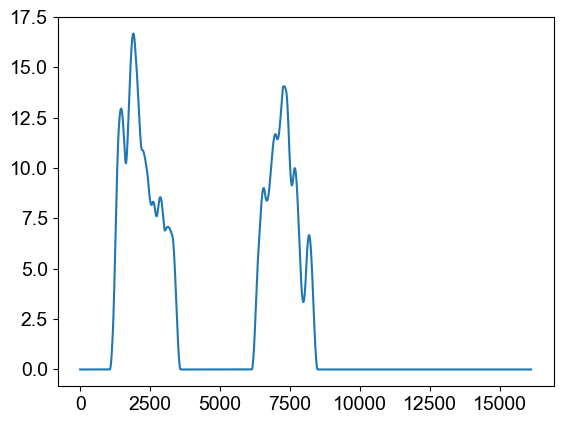

In [ ]:

file_path = "/Users/nmt121/Desktop/DATA/S1/E3_MB01_Day14High_28.pkl"

with open(file_path, "rb") as f:
    data = pickle.load(f)

spike_array = data["MU"]  
fs = 2048  
fr_exp = spikes_to_firing_rate(spike_array, fs, window_duration=0.3)
fr_exp.T.shape
plt.plot(fr_exp[0,:])

In [65]:
data["Idx_MU_Pair"]  


array([9, 3], dtype=uint8)

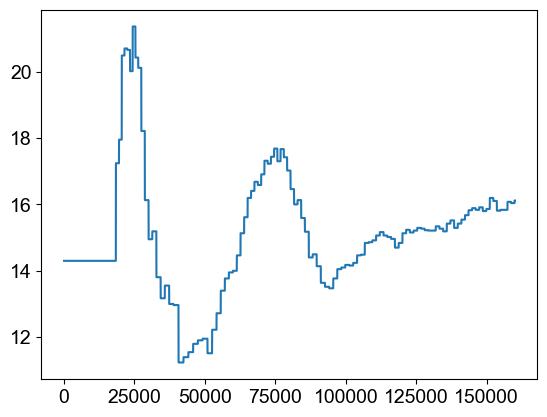

In [80]:
file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/all_rates_full14.jld2" 
with h5py.File(file_path, "r") as f:
    fr_sim = f["rates_full"][:]  

fr_sim.shape
plt.plot(fr_sim[:,3])

In [69]:
# downsample simulation to experimental length
target_len = fr_exp.shape[1]
fr_sim_resampled = resample(fr_sim.T, target_len, axis=1)
print(fr_sim_resampled.shape)  # (181, 43264)

(181, 43264)


In [70]:
n_exp, T = fr_exp.shape
n_sim, _ = fr_sim_resampled.shape

corr_matrix = np.zeros((n_exp, n_sim))
for i in range(n_exp):
    for j in range(n_sim):
        corr_matrix[i, j] = pearsonr(fr_exp[i], fr_sim_resampled[j])[0]



Experimental neuron 0 ↔ Simulated neuron 66 | r = 0.249
Experimental neuron 1 ↔ Simulated neuron 27 | r = 0.697
Experimental neuron 2 ↔ Simulated neuron 55 | r = 0.363
Experimental neuron 3 ↔ Simulated neuron 23 | r = 0.490
Experimental neuron 4 ↔ Simulated neuron 66 | r = 0.341
Experimental neuron 5 ↔ Simulated neuron 27 | r = 0.685
Experimental neuron 6 ↔ Simulated neuron 55 | r = 0.420
Experimental neuron 7 ↔ Simulated neuron 50 | r = 0.682
Experimental neuron 8 ↔ Simulated neuron 68 | r = 0.436
Experimental neuron 9 ↔ Simulated neuron 51 | r = 0.536
Experimental neuron 10 ↔ Simulated neuron 55 | r = 0.271
Experimental neuron 11 ↔ Simulated neuron 66 | r = 0.357
Experimental neuron 12 ↔ Simulated neuron 66 | r = 0.433
Experimental neuron 13 ↔ Simulated neuron 27 | r = 0.335
Experimental neuron 14 ↔ Simulated neuron 55 | r = 0.389


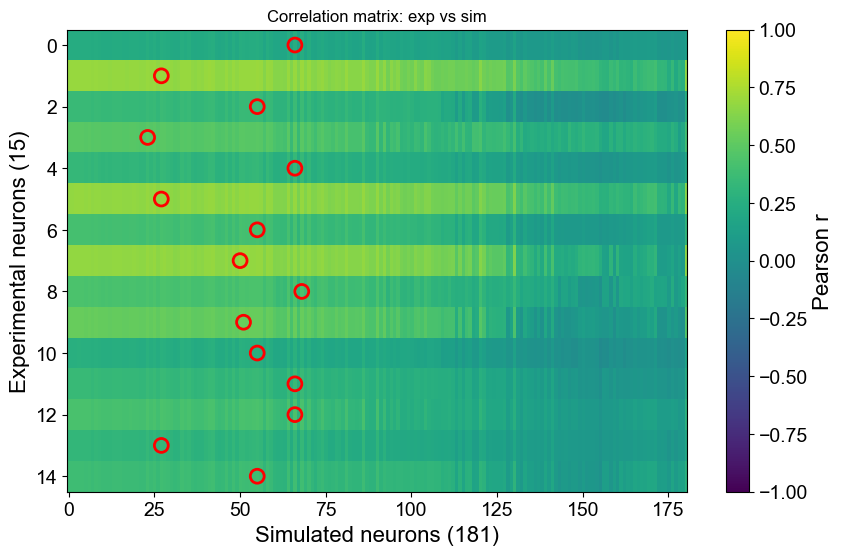

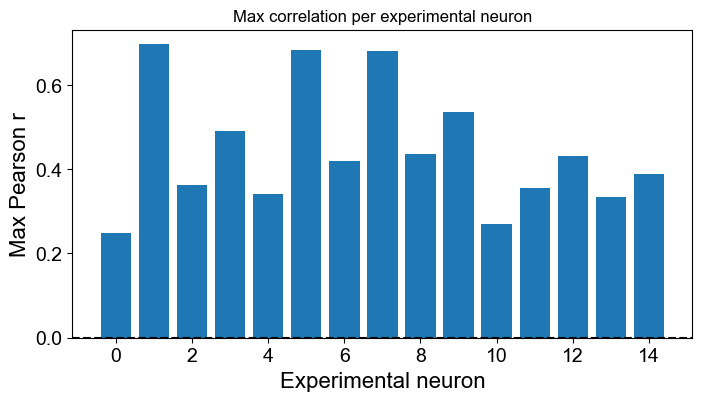

In [71]:
# 1. Compute max per row
max_vals = corr_matrix.max(axis=1)   # length = 15
best_match = corr_matrix.argmax(axis=1)  # index of best simulated neuron per row

# Print matches
for exp_idx, (sim_idx, corr) in enumerate(zip(best_match, max_vals)):
    print(f"Experimental neuron {exp_idx} ↔ Simulated neuron {sim_idx} | r = {corr:.3f}")

# 2. Plot the heatmap + red markers
plt.figure(figsize=(10,6))
im = plt.imshow(corr_matrix, aspect='auto', cmap='viridis', vmin=-1, vmax=1)
# im.savefig("/Users/nmt121/Desktop/corr.pdf", dpi=300, bbox_inches='tight')

plt.colorbar(im, label="Pearson r")
plt.xlabel("Simulated neurons (181)")
plt.ylabel("Experimental neurons (15)")
plt.title("Correlation matrix: exp vs sim")

# add red circle markers on maxima
for exp_idx, sim_idx in enumerate(best_match):
    plt.scatter(sim_idx, exp_idx, s=100, facecolors='none', edgecolors='red', linewidths=2)
fig.savefig("/Users/nmt121/Desktop/Figures/corr_maxvals_day1.pdf", dpi=300, bbox_inches='tight')

plt.show()

# 3. Plot the max values per row as a bar plot
plt.figure(figsize=(8,4))
plt.bar(np.arange(len(max_vals)), max_vals, color="C0")
plt.axhline(0, color='k', linestyle='--')
plt.ylabel("Max Pearson r")
plt.xlabel("Experimental neuron")
plt.title("Max correlation per experimental neuron")
fig.savefig("/Users/nmt121/Desktop/Figures/corr_maxvals_day1.pdf", dpi=300, bbox_inches='tight')
plt.show()